# Research Title
## Comparative Evaluation of Classical Statistical Time Series Models for Equity Index Forecasting

### Research Objective
Evaluate whether forecasting on stationary transformed series provides more reliable forecasts than modelling raw prices, and compare classical forecasting methods using multiple error metrics.

### Research Questions
1. Which statistical model provides the best forecasting performance?
2. Does stationarity improve forecasting quality?
3. How do baseline methods compare with ARIMA-family models?

### Hypotheses
- **H0:** There is no significant difference among forecasting models.
- **H1:** ARIMA-family models outperform baseline methods.

## Literature Background
- Financial price series are generally non-stationary.
- Box–Jenkins methodology recommends identification, estimation, diagnostic checking, and forecasting.
- Many studies recommend modelling returns instead of raw prices because returns are closer to stationary.

**This notebook experimentally verifies these ideas on Indian market data.**

## Methodology
1. Data Collection
2. Data Cleaning
3. Exploratory Analysis
4. Stationarity Testing (ADF)
5. Transformation (Log Returns)
6. Model Identification (ACF/PACF)
7. Forecasting
8. Residual Diagnostics
9. Model Comparison
10. Discussion & Conclusions

## Model Assumptions
| Model | Key Assumption |
|---|---|
| Mean/Naive | Historical level is informative |
| AR | Stationary process with autoregressive dependence |
| MA | Errors are serially correlated |
| ARMA | Stationary linear process |
| ARIMA | Differencing achieves stationarity |
| SARIMA | Seasonal structure exists |
| SARIMAX | Exogenous variables add predictive value |

## Discussion Template
After every experiment discuss:
- Why did this model perform this way?
- Were assumptions satisfied?
- What do residual diagnostics indicate?
- How could the model be improved?

## Threats to Validity
- Single market/index.
- Daily frequency only.
- Structural breaks may exist.
- No transaction costs considered.
- Results may not generalize to all financial assets.

## Final Conclusions
Summarize:
1. Best model.
2. Worst model.
3. Practical implications.
4. Limitations.
5. Future work (Prophet, ETS, ML/DL models, walk-forward validation).

### Importing all the necessary libraries and prerequisites

In [1]:
import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.graphics.tsaplots as sgt
import statsmodels.tsa.stattools as sts
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from scipy.stats import chi2
from arch import arch_model
import seaborn as sns
import yfinance
import warnings
warnings.filterwarnings("ignore")
sns.set()

### ***WORKING ON SENSEX STOCK INDEX***

#### **---Importing data---**

In [2]:
raw_sensex_data=pd.read_csv('BSE_Sensex_30_Historical_Data.csv')
raw_sensex_data.tail()

,Date,Price,Open,High,Low,Vol.
4049,01/08/2010,"17,540.29","17,603.87","17,658.12","17,508.96",17.30M
4050,01/07/2010,"17,615.72","17,701.97","17,733.34","17,566.54",17.96M
4051,01/06/2010,"17,701.13","17,719.47","17,790.33","17,636.71",21.46M
4052,01/05/2010,"17,686.24","17,555.77","17,729.78","17,555.77",27.00M
4053,01/04/2010,"17,558.73","17,473.45","17,582.84","17,378.38",28.18M


In [3]:
# making a copy of our data
df_sensex=raw_sensex_data.copy()
df_sensex.describe()

,Date,Price,Open,High,Low,Vol.
count,4054,4054,4054,4054,4054,4054
unique,4054,4054,4046,4052,4053,1800
top,01/04/2010,"17,558.73","65,503.85","28,143.28","25,769.81",9.91M
freq,1,1,2,2,2,10


### *As we can see our data is stored in string so we have to chang its data type*

In [4]:
# Remove commas and convert to numeric
cols = ['Price', 'Open', 'High', 'Low']
for col in cols:
    df_sensex[col] = df_sensex[col].str.replace(',', '').astype(float)

# Now describe() will show mean, std, quantiles etc.
df_sensex.describe()

,Price,Open,High,Low
count,4054.000000,4054.000000,4054.000000,4054.000000
mean,40055.364383,40085.868202,40278.706593,39835.540932
std,21215.300870,21217.314629,21301.818795,21121.862624
min,15175.080000,15436.120000,15440.100000,15135.860000
25%,20977.840000,20993.035000,21122.455000,20906.347500
50%,33330.000000,33378.905000,33599.080000,33155.755000
75%,57969.487500,58028.215000,58266.412500,57639.687500
max,85836.120000,86065.920000,86159.020000,85577.820000


### *Deleting the column which are not necessary*

In [5]:
del df_sensex['Open']
del df_sensex['High']
del df_sensex['Low']
del df_sensex['Vol.']

In [6]:
# Now we only have closing price with column name as price
df_sensex.head()

,Date,Price
0,05/08/2026,77328.19
1,05/07/2026,77844.52
2,05/06/2026,77958.52
3,05/05/2026,77017.79
4,05/04/2026,77269.40


In [7]:
# setting date as index
df_sensex['Date'] = pd.to_datetime(df_sensex['Date'])
df_sensex.set_index('Date', inplace=True)
df_sensex.head()

,Price
Date,
2026-05-08,77328.19
2026-05-07,77844.52
2026-05-06,77958.52
2026-05-05,77017.79
2026-05-04,77269.40


In [8]:
# setting my data into business days
df_sensex=df_sensex.asfreq('b')
print(df_sensex.isna().sum())

Price    229
dtype: int64


### As we can see that our data has 229 missing values so we have to fill it 

In [9]:
df_sensex=df_sensex.ffill()
print(df_sensex.isna().sum())

Price    0
dtype: int64


### *now there is no NA values in our data , so we can proceed*

### **Now we have to plot the graph of price and visualize it and check what our data tells us**

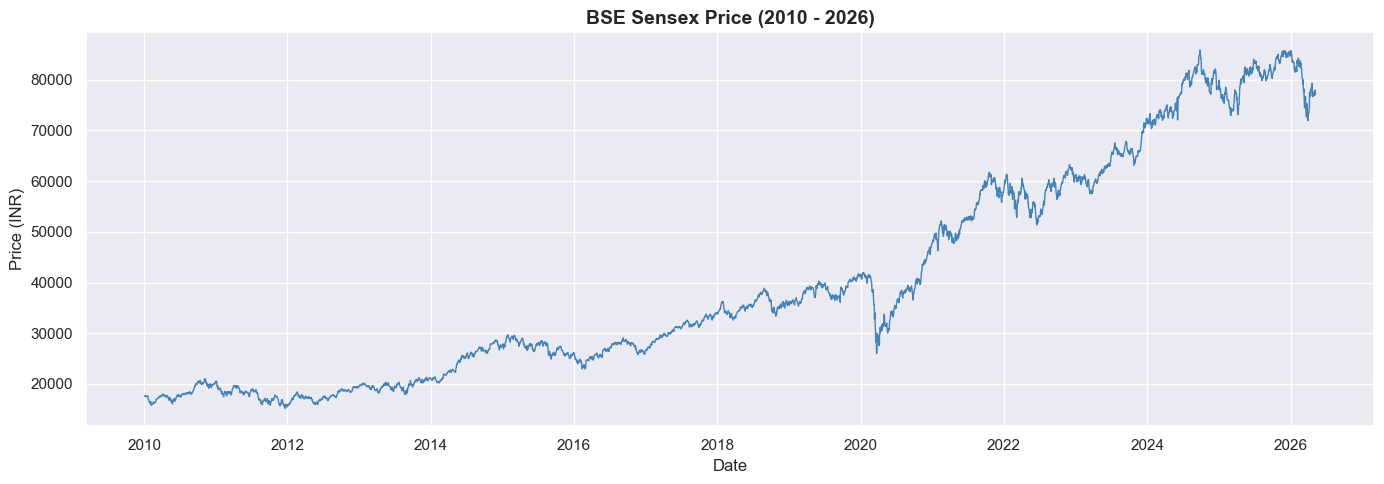

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df_sensex['Price'], color='steelblue', linewidth=1)
plt.title('BSE Sensex Price (2010 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

## *As we can see there is long term trend but no seasonality and intuitively see the data is not stationary*

### **NOW LETS CONFIRM IF OUR "PRICE" DATA IS STATIONARY OR NOT BU THE HELP OF AD-FULLER TEST**

In [11]:
sts.adfuller(df_sensex['Price'])

(np.float64(0.09982070950403851),
 np.float64(0.9660488509585018),
 29,
 4235,
 {'1%': np.float64(-3.4318950455880155),
  '5%': np.float64(-2.8622227159377456),
  '10%': np.float64(-2.5671334151787892)},
 np.float64(62905.73050839534))

### **As we can see that our p-value = 0.97 which is > 0.05 and test-statistic > table value for all confidence interval , we can conclude that our data is not stationary**

## **TO MAKE IT STATIONARY WE HAVE TO APPLY LOG RETURNS ON OUR DATA**

In [12]:
# Log Return
df_sensex['log_return'] = np.log(df_sensex['Price'] / df_sensex['Price'].shift(1))
df_sensex.head()

,Price,log_return
Date,,
2010-01-04,17558.73,NaN
2010-01-05,17686.24,0.007236
2010-01-06,17701.13,0.000842
2010-01-07,17615.72,-0.004837
2010-01-08,17540.29,-0.004291


### **Now we have to visualize our log return and check for stationarity of our log returns**

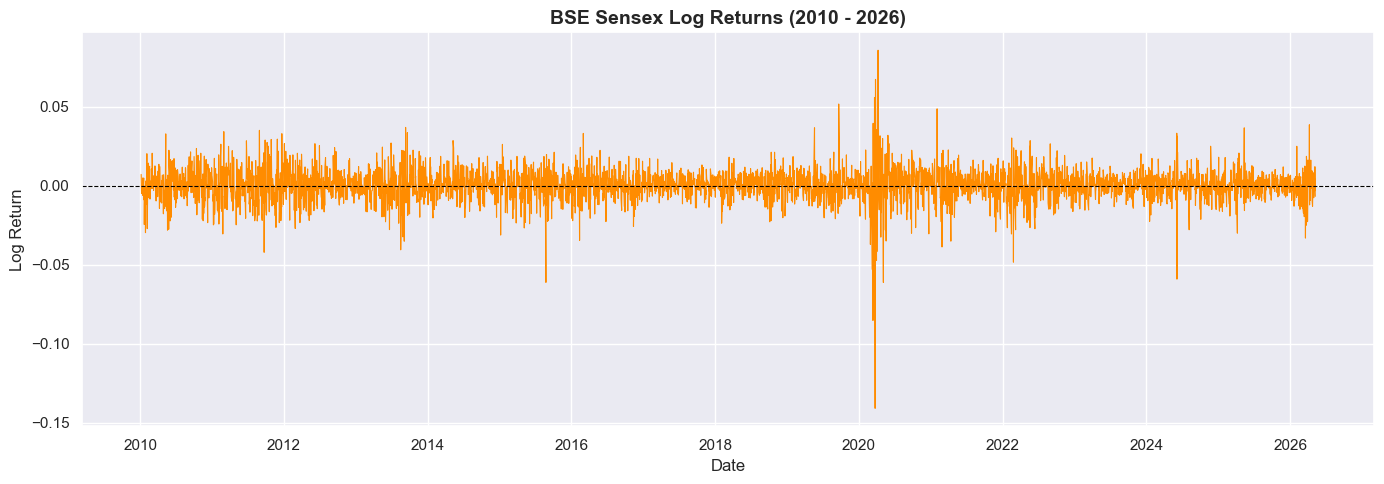

In [13]:
plt.figure(figsize=(14, 5))
plt.plot(df_sensex['log_return'], color='darkorange', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('BSE Sensex Log Returns (2010 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.tight_layout()
plt.show()

### **from here we can see that there is no trend and intutively see that the data is stationary, bnut for confirmation we have to apply AD-fuller test**

#### ***We can also confirm it by rolling mean graph then at the end we can check it by ad-fuller test***

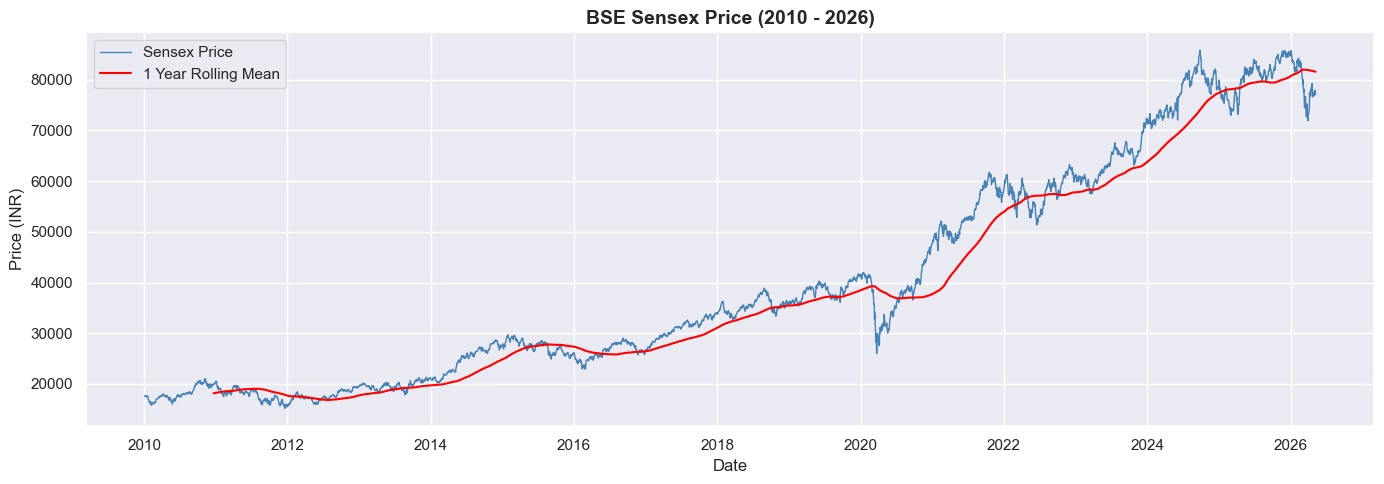

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(df_sensex['Price'], color='steelblue', linewidth=1, label='Sensex Price')
plt.plot(df_sensex['Price'].rolling(252).mean(), color='red', linewidth=1.5, label='1 Year Rolling Mean')
plt.title('BSE Sensex Price (2010 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price (INR)')
plt.legend()
plt.tight_layout()
plt.show()

### The rolling mean keeps shifting upward over time — which is a classic visual sign of non-stationarity. A stationary series would have a flat, constant rolling mean.

In [15]:
sts.adfuller(df_sensex['log_return'].dropna())

(np.float64(-19.477435542126088),
 0.0,
 10,
 4253,
 {'1%': np.float64(-3.431888502528218),
  '5%': np.float64(-2.862219825475238),
  '10%': np.float64(-2.567131876434272)},
 np.float64(-26919.826648625552))

## As we can see from here that p-value < 0.05 and test-statistic < table value ,so our data is stationary, now we can proceed furthur

### **---NOW WE HAVE TO SPLIKIT THE DATA IN 80-20 RATIO---**

In [16]:
sensex_train=df_sensex.iloc[:int(len(df_sensex)*0.8)]
sensex_test=df_sensex.iloc[int(len(df_sensex)*0.8):]

In [17]:
# shape of train and test data

print(f'Shape of training data -> {sensex_train.shape}')
print(f'Shape of testing data -> {sensex_test.shape}')

Shape of training data -> (3412, 2)
Shape of testing data -> (853, 2)


### *Visualizing the data*

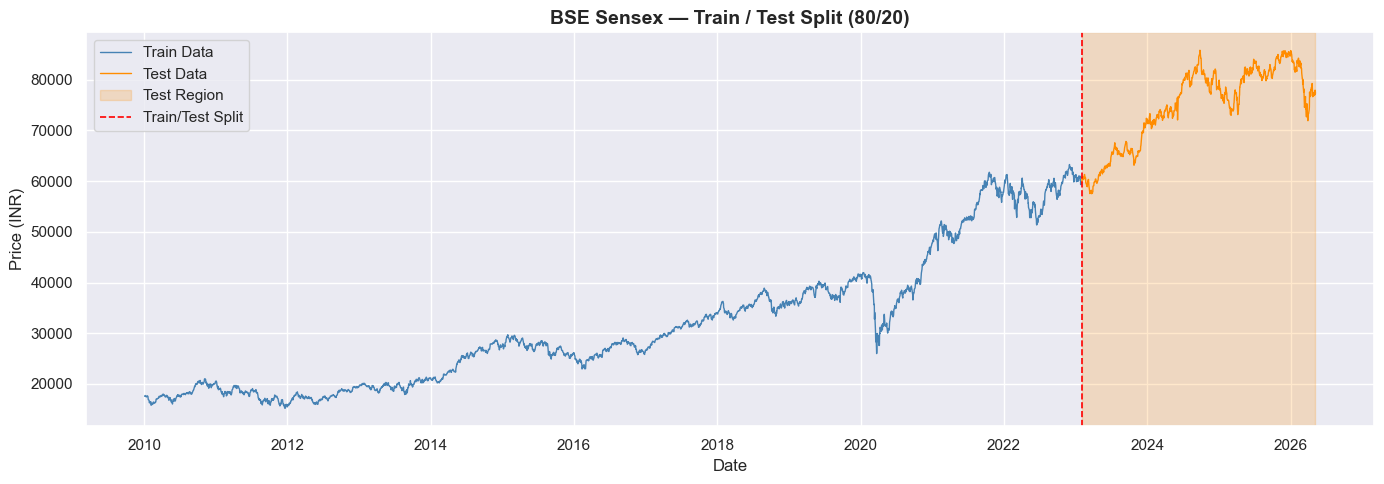

In [18]:
plt.figure(figsize=(14, 5))

# Plot train data
plt.plot(sensex_train.index, sensex_train['Price'], color='steelblue', linewidth=1, label='Train Data')

# Plot test data
plt.plot(sensex_test.index, sensex_test['Price'], color='darkorange', linewidth=1, label='Test Data')

# Shaded region for test data
plt.axvspan(sensex_test.index[0], sensex_test.index[-1], alpha=0.2, color='darkorange', label='Test Region')

# Split line
plt.axvline(sensex_test.index[0], color='red', linewidth=1.2, linestyle='--', label='Train/Test Split')

plt.title('BSE Sensex — Train / Test Split (80/20)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price (INR)')
plt.legend()
plt.tight_layout()
plt.show()

## **NEXT**-- "We plot the ACF and PACF of log returns to:
1. Test whether Sensex follows a random walk
   (no autocorrelation = random walk = hard to predict)
2. Check if any significant correlation exists 
   between past and present returns
3. Determine the optimal p and q values 
   for our AR and MA models"

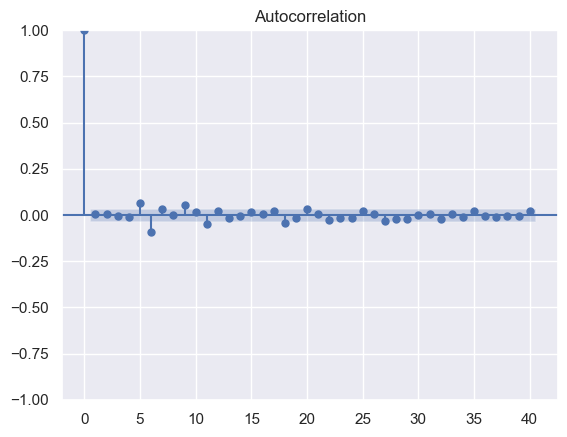

In [19]:
# Plotting ACF
sgt.plot_acf(sensex_train['log_return'].dropna(),lags=40);

"The ACF plot of Sensex log returns shows that 
most autocorrelations at all lags fall within 
the 95% confidence bands (blue region), indicating 
that the log returns are largely uncorrelated with 
their past values. This suggests that Sensex closely 
follows a random walk, meaning past returns have 
very little predictive power over future returns.
This also explains why AR and MA models 
will have limited forecasting ability on this data."

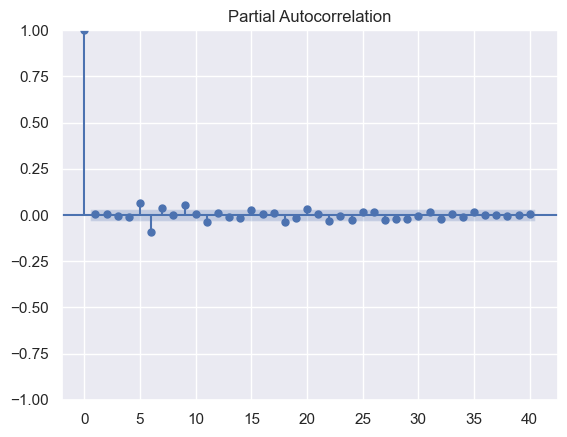

In [20]:
# Plotting PACF
sgt.plot_pacf(sensex_train['log_return'].dropna(),lags=40);

"The PACF plot also shows significant spikes at 
lag 5 and lag 6, indicating that after removing 
the effect of intermediate lags, there is still 
a direct relationship between current returns and 
returns from 5 and 6 days ago. Based on this, 
we select p = 6 as the order for our AR model."

## ***NOW LET'S PROCEED FURTHUR AND PROCEED WITH BASELINE MODELS***

"Before applying advanced time series models like 
AR and MA, we first establish baseline models. 
Baseline models are simple forecasting methods 
that require minimal assumptions and computation. 

They serve as a benchmark — any advanced model 
we build must perform better than these baselines 
to be considered useful. If our AR or MA model 
cannot beat a simple baseline, it means the model 
is not adding any value.

We apply the following 3 baseline models on the 
Sensex closing price:

1. Naive Model — assumes tomorrow's price equals 
   today's price

2. Simple Average Model — assumes tomorrow's price 
   equals the average of all past prices

3. Moving Average Model — assumes tomorrow's price 
   equals the average of the last n days

After forecasting, we evaluate each model using 
error metrics (MAE, RMSE, MAPE) and compare 
their performance."

## ***-------1.) NAIVE MODEL--------***

In [21]:
# Last value of train data
naive_forecast = sensex_test['Price'].copy()
naive_forecast[:] = sensex_train['Price'].iloc[-1]
sensex_test['naive_forecast'] = sensex_train['Price'].iloc[-1]
sensex_test.head()

,Price,log_return,naive_forecast
Date,,,
2023-02-01,59708.08,0.002653,59549.9
2023-02-02,59932.24,0.003747,59549.9
2023-02-03,60841.88,0.015064,59549.9
2023-02-06,60506.90,-0.005521,59549.9
2023-02-07,60286.04,-0.003657,59549.9


### **Now lets plot our data and visualize**

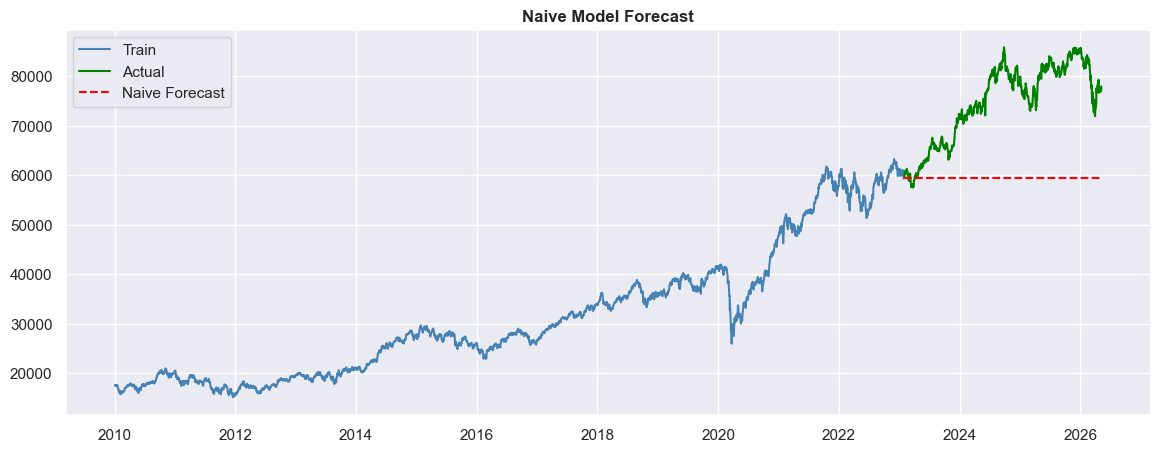

In [22]:
# Then plot
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['naive_forecast'], color='red', linestyle='--', label='Naive Forecast')
plt.title('Naive Model Forecast', fontweight='bold')
plt.legend()
plt.show()

## As we can see the naive model is far off from the test data , now we have to find the errors of naive model

In [23]:
# ERROR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# MAE
mae = mean_absolute_error(sensex_test['Price'], sensex_test['naive_forecast'])

# RMSE
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['naive_forecast']))

# MAPE
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['naive_forecast']) / sensex_test['Price'])) * 100

print('=== Naive Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== Naive Model Errors ===
MAE  : 15298.83
RMSE : 17110.46
MAPE : 19.54%


"We evaluate our models using three error metrics:

MAE tells us the average error in rupees — 
how far off our forecast is on a typical day.

RMSE tells us if our model is making large 
errors on some days — it penalizes big mistakes 
more than small ones.

MAPE tells us the error as a percentage — 
making it easy to compare across all models 
regardless of the price level."

In [24]:
# STORING RESULT FOR LATER COMPARISION
results = pd.DataFrame(columns=['Model', 'MAE', 'RMSE', 'MAPE'])
results.loc[0] = ['Naive', mae, rmse, mape]
print(results)

   Model           MAE         RMSE       MAPE
0  Naive  15298.834666  17110.45582  19.542711


## ***-------2.) SIMPLE AVERAGE MODEL--------***

In [25]:
# Simple Average Model
# Forecast = mean of all train prices
sensex_test['avg_forecast'] = sensex_train['Price'].mean()
sensex_test.head()

,Price,log_return,naive_forecast,avg_forecast
Date,,,,
2023-02-01,59708.08,0.002653,59549.9,31415.277254
2023-02-02,59932.24,0.003747,59549.9,31415.277254
2023-02-03,60841.88,0.015064,59549.9,31415.277254
2023-02-06,60506.90,-0.005521,59549.9,31415.277254
2023-02-07,60286.04,-0.003657,59549.9,31415.277254


### **Now lets plot our data and visualize**

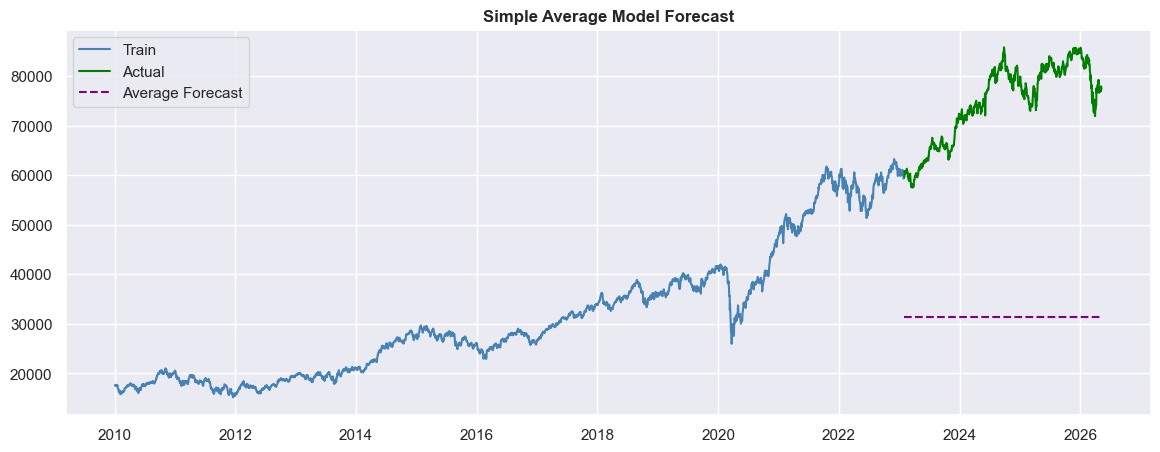

In [26]:
# Plot
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['avg_forecast'], color='purple', linestyle='--', label='Average Forecast')
plt.title('Simple Average Model Forecast', fontweight='bold')
plt.legend()
plt.show()

## As we can see the naive model is far off from the test data , now we have to find the errors of naive model

In [27]:
# Error Metrics
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['avg_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['avg_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['avg_forecast']) / sensex_test['Price'])) * 100

print('=== Simple Average Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== Simple Average Model Errors ===
MAE  : 43369.22
RMSE : 44063.18
MAPE : 57.50%


## As we can see from MAPE that this model is worse predictor than the previous one 

### **This proves that simple average is useless for trending data like Sensex**

In [28]:
# Add to results
results.loc[1] = ['Simple Average', mae, rmse, mape]
print(results)

            Model           MAE          RMSE       MAPE
0           Naive  15298.834666  17110.455820  19.542711
1  Simple Average  43369.222242  44063.183208  57.496675


### ***ALL THE GRAPH IN ONE GRAPH***

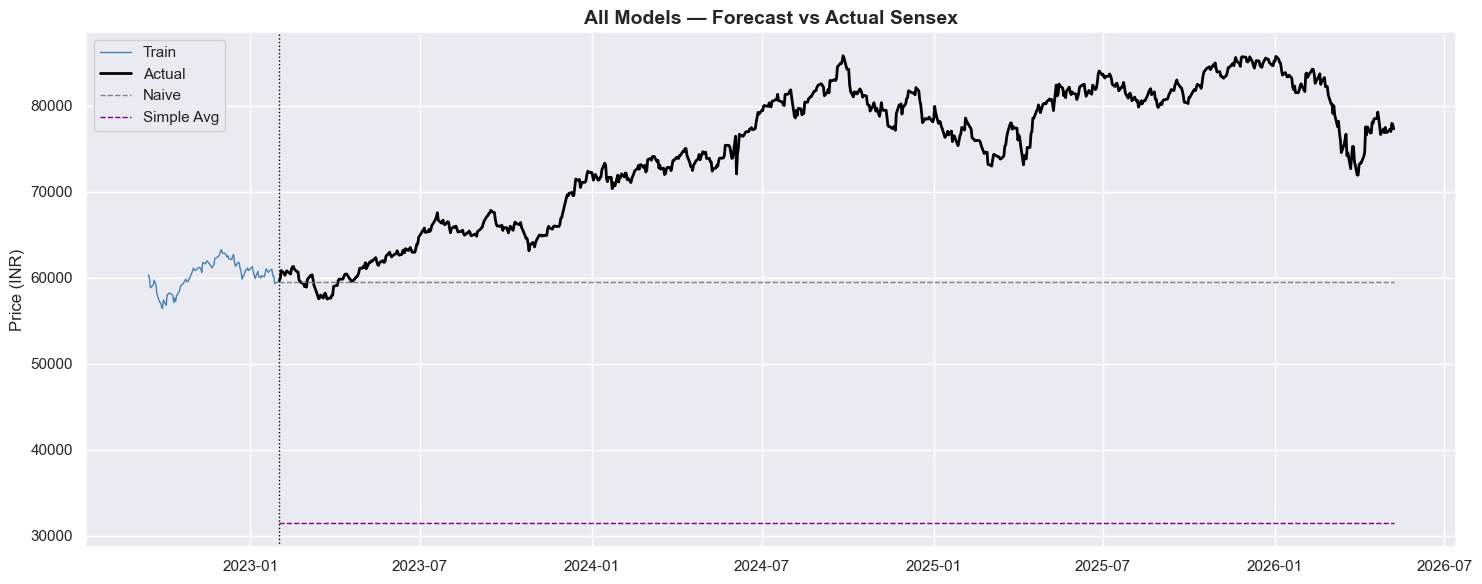

In [29]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## ***BAR GRAPH***

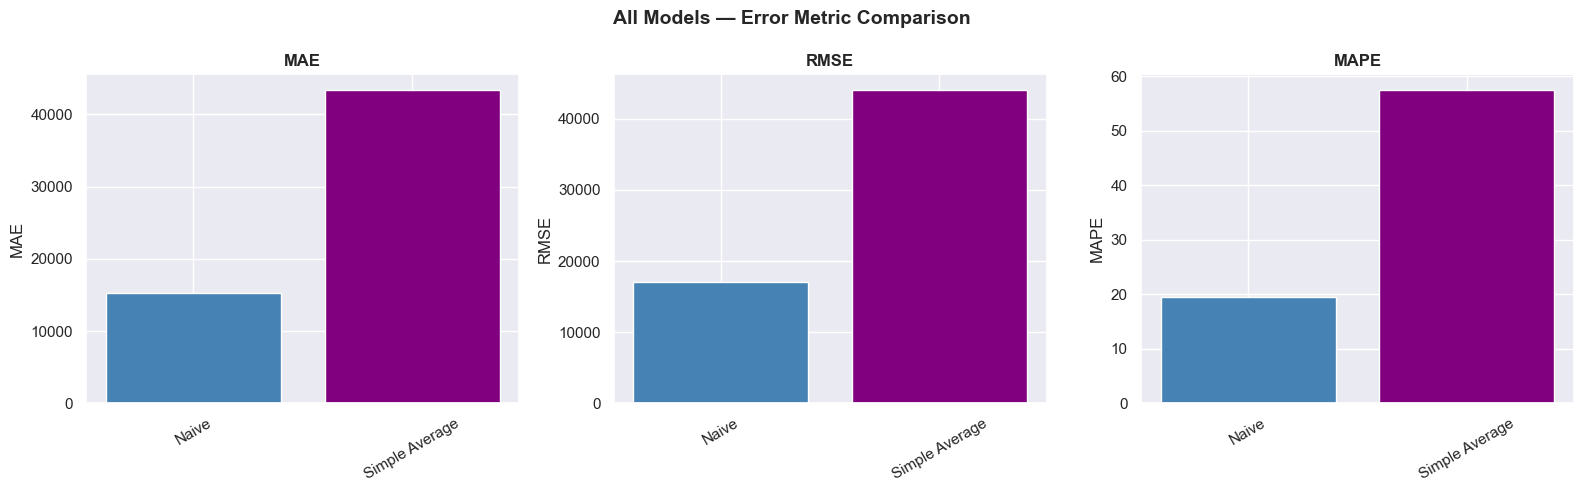

In [30]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange','red','green'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## ***-------3.)FORCASTING LAST 30 DAYS MEAN --------***

In [31]:
# Moving Average Model
# Forecast = average of last 30 days of train data
window = 30
sensex_test['30 days mean'] = sensex_train['Price'].rolling(window=window).mean().iloc[-1]
sensex_test.head()

,Price,log_return,naive_forecast,avg_forecast,30 days mean
Date,,,,,
2023-02-01,59708.08,0.002653,59549.9,31415.277254,60488.815333
2023-02-02,59932.24,0.003747,59549.9,31415.277254,60488.815333
2023-02-03,60841.88,0.015064,59549.9,31415.277254,60488.815333
2023-02-06,60506.90,-0.005521,59549.9,31415.277254,60488.815333
2023-02-07,60286.04,-0.003657,59549.9,31415.277254,60488.815333


### **Now lets plot our data and visualize**

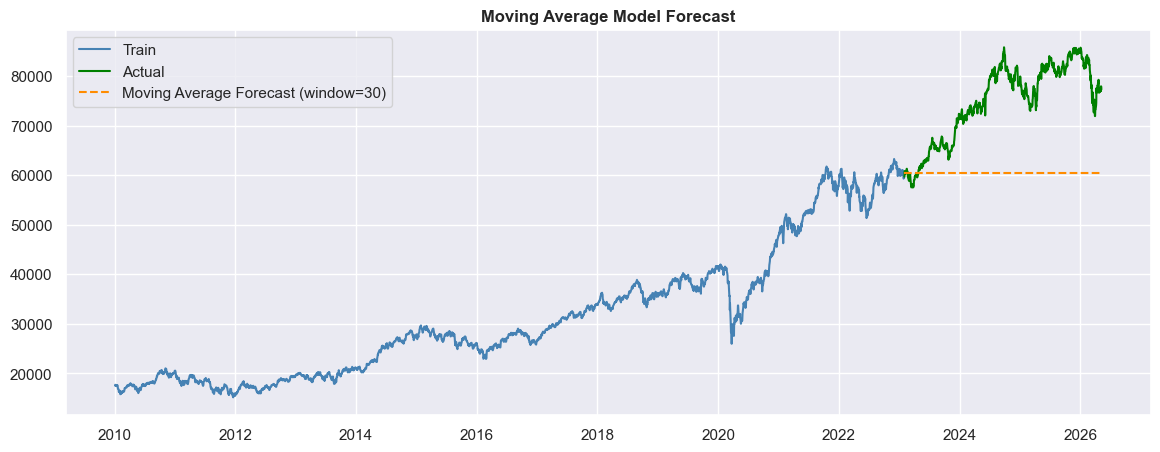

In [32]:
# Plot
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['30 days mean'], color='darkorange', linestyle='--', label=f'Moving Average Forecast (window={window})')
plt.title('Moving Average Model Forecast', fontweight='bold')
plt.legend()
plt.show()

## As we can see it better than the previous two models, now lets proceed and find the error

In [33]:
# Error Metrics
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['30 days mean'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['30 days mean']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['30 days mean']) / sensex_test['Price'])) * 100
print('=== Moving Average Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== Moving Average Model Errors ===
MAE  : 14442.16
RMSE : 16280.09
MAPE : 18.41%


Here the MAPE is less that the above models but far from good predictor so now we have to proceed with advance model 

In [34]:
# Add to results
results.loc[2] = ['30 days mean', mae, rmse, mape]
print(results)

            Model           MAE          RMSE       MAPE
0           Naive  15298.834666  17110.455820  19.542711
1  Simple Average  43369.222242  44063.183208  57.496675
2    30 days mean  14442.163686  16280.087907  18.412019


### ***ALL THE DATA IN ONE GRAPH***

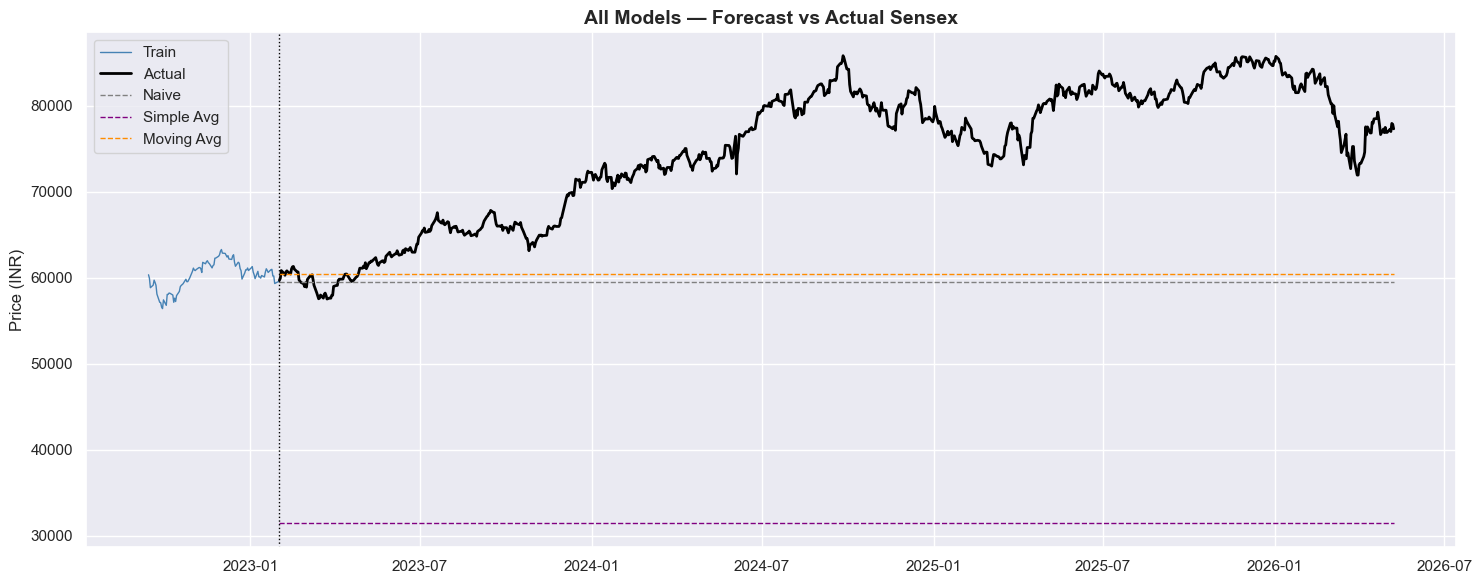

In [35]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## ***BAR GRAPH***

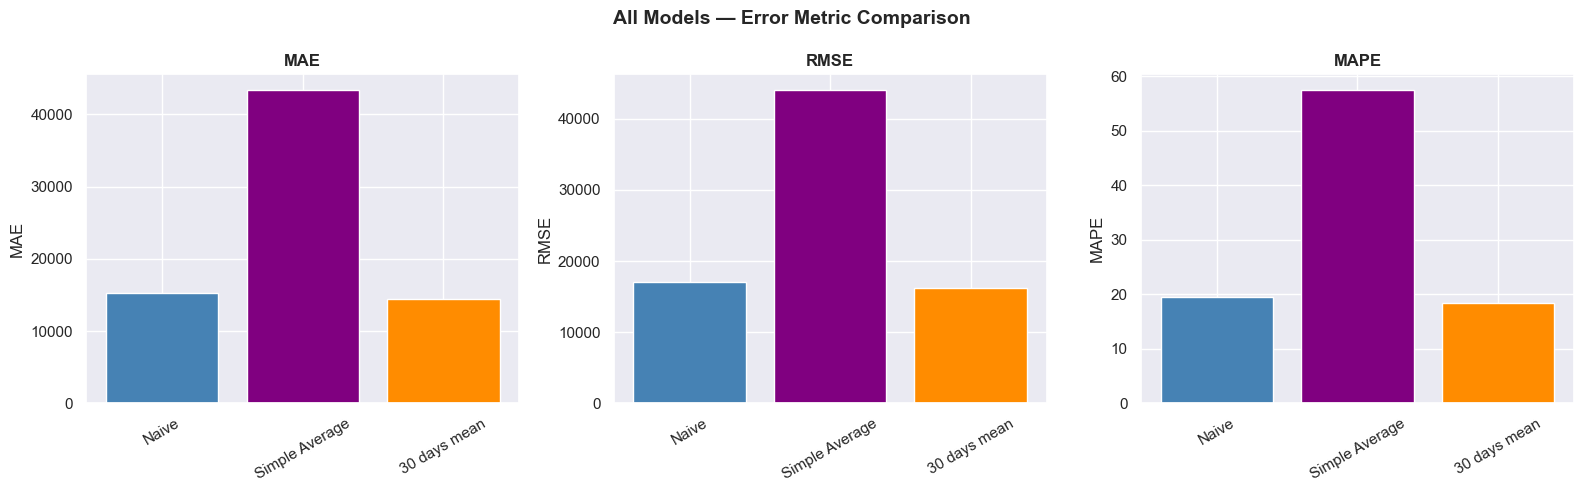

In [36]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange','red','green'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **ADVANCED MODELS**

## ***-------4.)AR model --------***

"After establishing our baseline models, we now 
apply the AR (AutoRegressive) model.

An AR model predicts future values using a 
linear combination of its own past values.
The equation is:

y(t) = c + φ1*y(t-1) + φ2*y(t-2) + ... + φp*y(t-p) + ε

Where:
y(t)      = current value we want to predict
c         = constant
φ         = coefficients (weights given to past values)
y(t-1)    = value from 1 period ago
p         = number of past values used (order)
ε         = error term

The key parameter is p (order) which tells the 
model how many past values to look at.

From our PACF plot we observed significant spikes 
at lag 5 and lag 6, therefore we will use p = 6 
for our AR model.

Important: AR model requires stationary data, 
which is why we fit it on log returns instead 
of raw prices. After forecasting log returns 
we convert them back to prices for comparison."

#### **First we have to find the order of the AR model then we can proceed for that we have to look at the PACF graph again**

### ***Why do we use PACF for AR order and ACF for MA order?***

"A common question is — why do we look at the 
PACF graph to find the order of AR model and 
not the ACF graph?

The answer lies in what each model uses for 
prediction and what each graph measures.

The AR model predicts future values using past 
actual values of the series. We need to find 
the direct relationship between current value 
and each past value. PACF measures exactly this 
— it shows the pure direct correlation between 
current and past values by removing the effect 
of all intermediate lags. So PACF tells us 
exactly at which lag the direct effect stops, 
and that becomes our AR order (p).

If we used ACF for AR order, we would get a 
wrong answer because ACF includes both direct 
and indirect effects mixed together, which would 
overestimate the number of lags needed.

Similarly the MA model predicts future values 
using past errors. ACF measures the total 
correlation including all indirect effects, 
which matches exactly how MA model works. 
So ACF is used to find MA order (q).

In simple terms:
PACF → direct effect only → AR model
ACF  → total effect       → MA model"

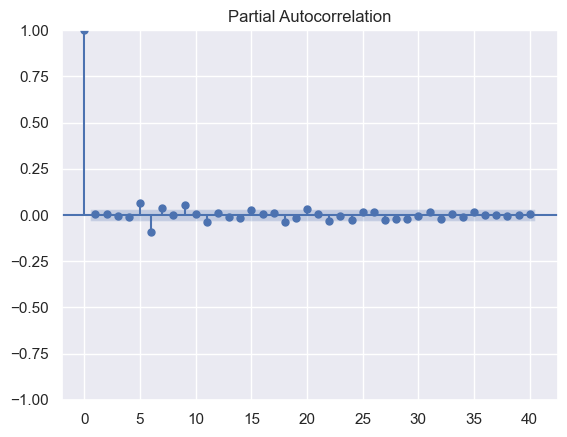

In [37]:
# Plotting PACF
sgt.plot_pacf(sensex_train['log_return'].dropna(),lags=40);

#### ***"From the PACF plot we can observe significant spikes at lag 5 and lag 6, which initially suggests that AR(5) or AR(6) could be the appropriate order for our AR model.***

However we cannot rely on the PACF plot alone 
to select the final order because:

1. PACF can sometimes show false significant 
   spikes due to randomness in the data

2. We need statistical confirmation that adding 
   each lag is actually improving the model 
   significantly

Therefore we will formally determine the best 
AR order by:

1. Fitting AR models from AR(1) to AR(6) 
   one by one

2. Checking AIC and BIC at each step
   → Lower AIC/BIC = better model

3. Applying the LLR (Log Likelihood Ratio) test 
   at each step to check if adding a new lag 
   significantly improves the model
   → p-value < 0.05 = significant improvement
   → p-value > 0.05 = no significant improvement

The model where LLR test becomes insignificant 
(p > 0.05) will be our final AR order."

In [38]:
## LLR test
def LLR_test(mod_1, mod_2, DF=1):
    L1 = mod_1.fit().llf
    L2 = mod_2.fit().llf
    LR = (2*(L2-L1))
    p = chi2.sf(LR, DF).round(3)
    return p

In [39]:
log_ret = sensex_train['log_return'].dropna()

# AR(1)
mod1 = ARIMA(log_ret, order=(1,0,0))
mod1_fitted = mod1.fit()
print('=== AR(1) ===')
print(f'AIC : {mod1_fitted.aic:.4f}')
print(f'BIC : {mod1_fitted.bic:.4f}')
print(mod1_fitted.summary())

=== AR(1) ===
AIC : -21320.9066
BIC : -21302.5024
                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                 3411
Model:                 ARIMA(1, 0, 0)   Log Likelihood               10663.453
Date:                Tue, 11 Aug 2026   AIC                         -21320.907
Time:                        15:36:57   BIC                         -21302.502
Sample:                    01-05-2010   HQIC                        -21314.330
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.899      0.058   -1.14e-05       0.001
ar.L1          0.0079      0.010      0.792      0.428      -0.012       0.027
si

In [40]:
log_ret = sensex_train['log_return'].dropna()

# AR(2)
mod2 = ARIMA(log_ret, order=(2,0,0))
mod1_fitted = mod2.fit()
print('=== AR(2) ===')
print(f'AIC : {mod1_fitted.aic:.4f}')
print(f'BIC : {mod1_fitted.bic:.4f}')
print(mod1_fitted.summary())

=== AR(2) ===
AIC : -21319.0740
BIC : -21294.5350
                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                 3411
Model:                 ARIMA(2, 0, 0)   Log Likelihood               10663.537
Date:                Tue, 11 Aug 2026   AIC                         -21319.074
Time:                        15:36:57   BIC                         -21294.535
Sample:                    01-05-2010   HQIC                        -21310.305
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.839      0.066   -2.35e-05       0.001
ar.L1          0.0078      0.010      0.756      0.450      -0.012       0.028
ar

In [41]:
# Applying LLR test and comparing AR(1) and AR(2)
print(LLR_test(mod1,mod2))

0.682


#### ***when adding more lags, the LLR test gives a  p-value of 0.682 which is greater than 0.05. This means the improvement is not statistically significant Therefore we prefer the simpler model following the principle of parsimony — always choose the simplest model that explains the data adequately.***

### ***FITTING AR(1) MODEL***

In [42]:
# Fit final AR(1) model
log_ret = sensex_train['log_return'].dropna()

final_ar = ARIMA(log_ret, order=(1,0,0)).fit()
print(final_ar.summary())

                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                 3411
Model:                 ARIMA(1, 0, 0)   Log Likelihood               10663.453
Date:                Tue, 11 Aug 2026   AIC                         -21320.907
Time:                        15:36:58   BIC                         -21302.502
Sample:                    01-05-2010   HQIC                        -21314.330
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.899      0.058   -1.14e-05       0.001
ar.L1          0.0079      0.010      0.792      0.428      -0.012       0.027
sigma2         0.0001   1.08e-06    103.951      0.0

### **Forecast and convert back to prices:**

In [43]:
# Forecast log returns for test period
forecast_log_ret = final_ar.forecast(steps=len(sensex_test))

# Convert log returns back to prices
last_train_price = sensex_train['Price'].iloc[-1]
ar_prices = []

for lr in forecast_log_ret:
    last_train_price = last_train_price * np.exp(lr)
    ar_prices.append(last_train_price)

# Store in test dataframe
sensex_test['ar_forecast'] = ar_prices

### **Now lets plot our data and visualize**

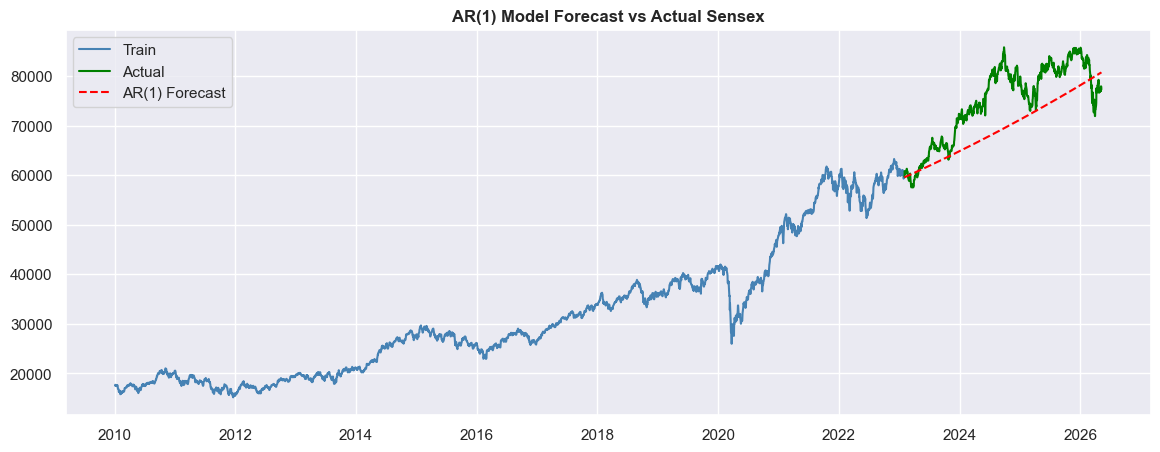

In [44]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['ar_forecast'], color='red', 
         linestyle='--', label='AR(1) Forecast')
plt.title('AR(1) Model Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

## As we can see it better than the previous baseline models, now lets proceed and find the error.

In [45]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['ar_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['ar_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['ar_forecast']) / sensex_test['Price'])) * 100

print('=== AR(1) Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== AR(1) Model Errors ===
MAE  : 5700.71
RMSE : 6663.51
MAPE : 7.35%


Here the MAPE is less that the above models but not enough good predictor so now we have to proceed with MA model

In [46]:
results.loc[3] = ['AR(1)', mae, rmse, mape]

### ***ALL THE DATA IN ONE GRAPH***

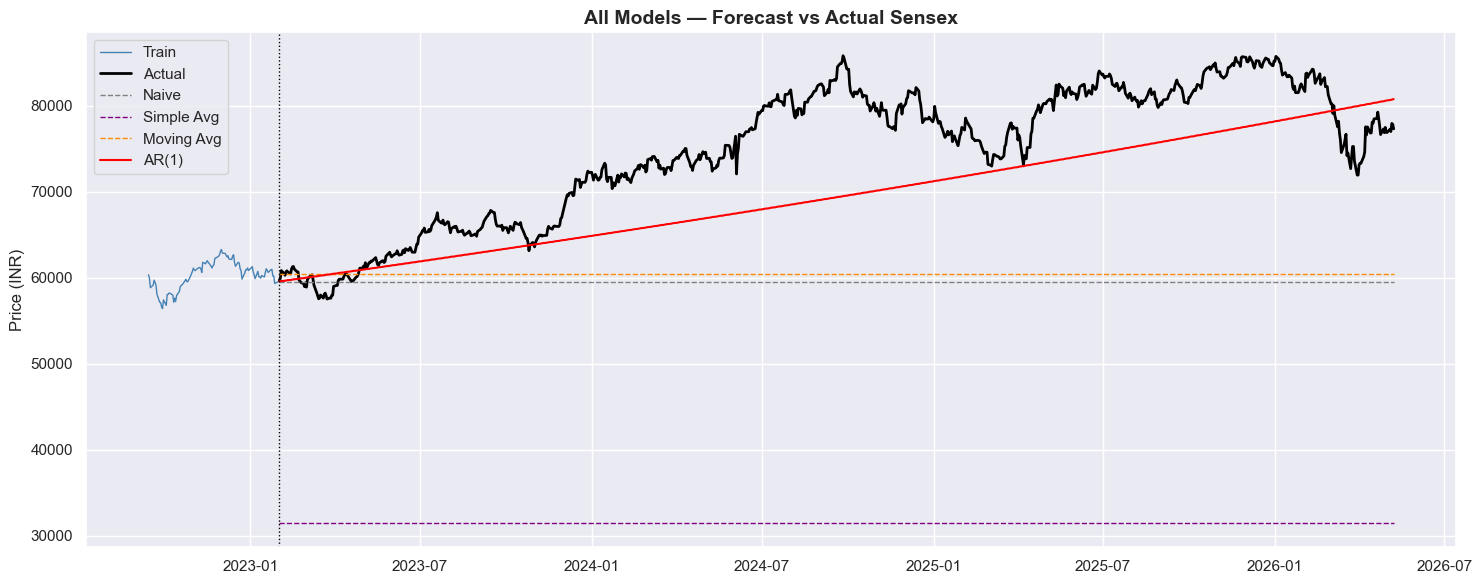

In [47]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'],    
         '-', color='red', linewidth=1.5, label='AR(1)')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## ***BAR GRAPH***

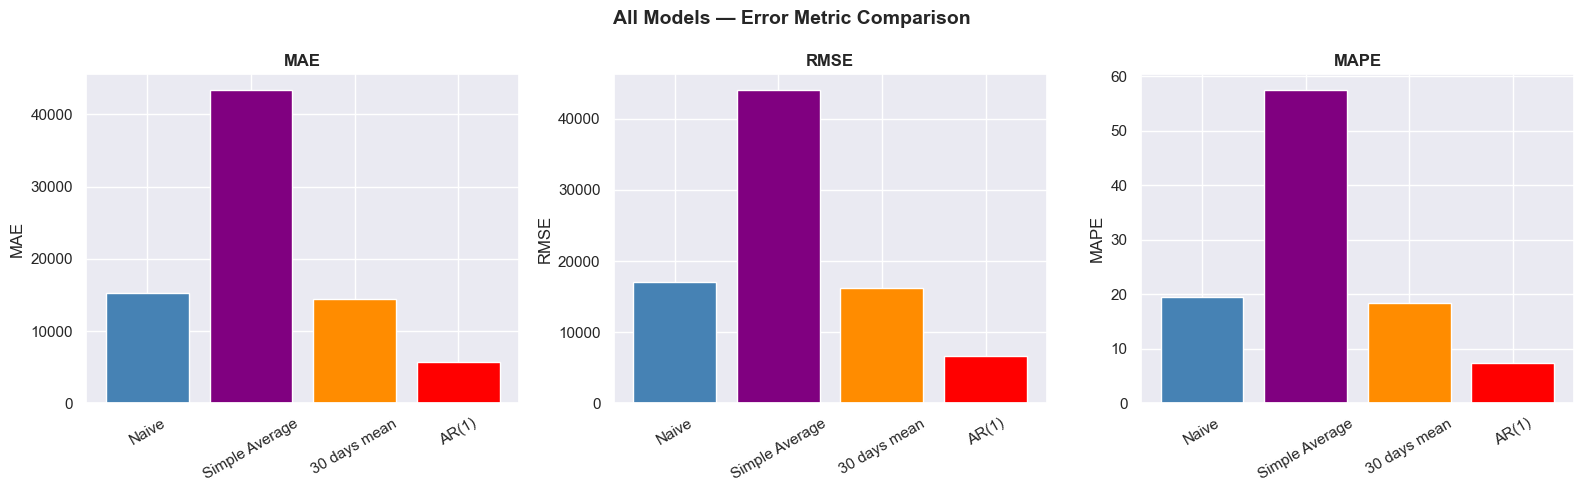

In [48]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange','red','green'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## ***-------5.)MA(moving average) model --------***

"After fitting the AR model, we now apply the 
MA (Moving Average) model.

Unlike the AR model which uses past actual values, 
the MA model predicts future values using past 
forecast errors (residuals).

The equation is:

y(t) = μ + ε(t) + θ1*ε(t-1) + θ2*ε(t-2) + ... + θq*ε(t-q)

Where:
y(t)    = current value we want to predict
μ       = mean of the series
ε(t)    = current error
θ       = coefficients (weights given to past errors)
q       = number of past errors used (order)

The key parameter is q (order) which tells the 
model how many past errors to look at.

From our ACF plot we observed significant spikes 
at lag 5 and lag 6, which suggests q = 5 or 6.

Just like AR model, we will formally confirm 
the best order by:

1. Fitting MA models from MA(1) to MA(6)
2. Checking AIC and BIC at each step
3. Applying LLR test at each step

MA model is fitted on log returns (stationary data) 
and predictions are converted back to prices 
for final comparison."

### **firstly we have to see the PACF graph and see what can we take out of that**

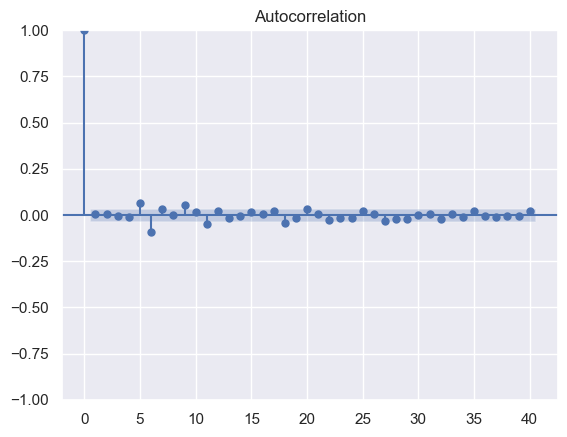

In [49]:
# Plotting ACF
sgt.plot_acf(sensex_train['log_return'].dropna(),lags=40);

### "From the ACF plot we observe significant spikes at lag 5 and lag 6, which suggests that MA(5) or MA(6) could be the appropriate order for our MA model. However just like the AR model,we cannot rely on ACF plot alone. We will formally confirm the best order using AIC, BIC and LLR test."

In [50]:
log_ret = sensex_train['log_return'].dropna()

# MA(1)
mod1_ma = ARIMA(log_ret, order=(0,0,1))
mod1_ma_fitted = mod1_ma.fit()
print('=== MA(1) ===')
print(f'AIC : {mod1_ma_fitted.aic:.4f}')
print(f'BIC : {mod1_ma_fitted.bic:.4f}')

=== MA(1) ===
AIC : -21320.9024
BIC : -21302.4981


In [51]:
# MA(2)
mod2_ma = ARIMA(log_ret, order=(0,0,2))
mod2_ma_fitted = mod2_ma.fit()
print('=== MA(2) ===')
print(f'AIC : {mod2_ma_fitted.aic:.4f}')
print(f'BIC : {mod2_ma_fitted.bic:.4f}')

# LLR test MA(1) vs MA(2)
print(f'\nLLR Test MA(1) vs MA(2) : {LLR_test(mod1_ma, mod2_ma)}')

=== MA(2) ===
AIC : -21319.0769
BIC : -21294.5379

LLR Test MA(1) vs MA(2) : 0.676


#### ***"The LLR test comparing MA(1) and MA(2) gives a p-value of 0.676 which is greater than 0.05. This means adding a second lag does not significantly improve the model. Therefore MA(1) is selected as our final MA model, following the principle of parsimony — always choose the simplest model that adequately explains the data."***

## ***fit MA(1) and forecast:***

In [52]:
# Fit final MA(1) model
final_ma = ARIMA(log_ret, order=(0,0,1)).fit()
print(final_ma.summary())

                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                 3411
Model:                 ARIMA(0, 0, 1)   Log Likelihood               10663.451
Date:                Tue, 11 Aug 2026   AIC                         -21320.902
Time:                        15:37:06   BIC                         -21302.498
Sample:                    01-05-2010   HQIC                        -21314.325
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.891      0.059   -1.29e-05       0.001
ma.L1          0.0079      0.010      0.795      0.427      -0.012       0.027
sigma2         0.0001   1.08e-06    104.097      0.0

In [53]:
# Forecast log returns
forecast_log_ret_ma = final_ma.forecast(steps=len(sensex_test))

In [54]:
# Convert back to prices
last_train_price = sensex_train['Price'].iloc[-1]
ma_prices = []

for lr in forecast_log_ret_ma:
    last_train_price = last_train_price * np.exp(lr)
    ma_prices.append(last_train_price)
# Store in test dataframe
sensex_test['ma_forecast'] = ma_prices

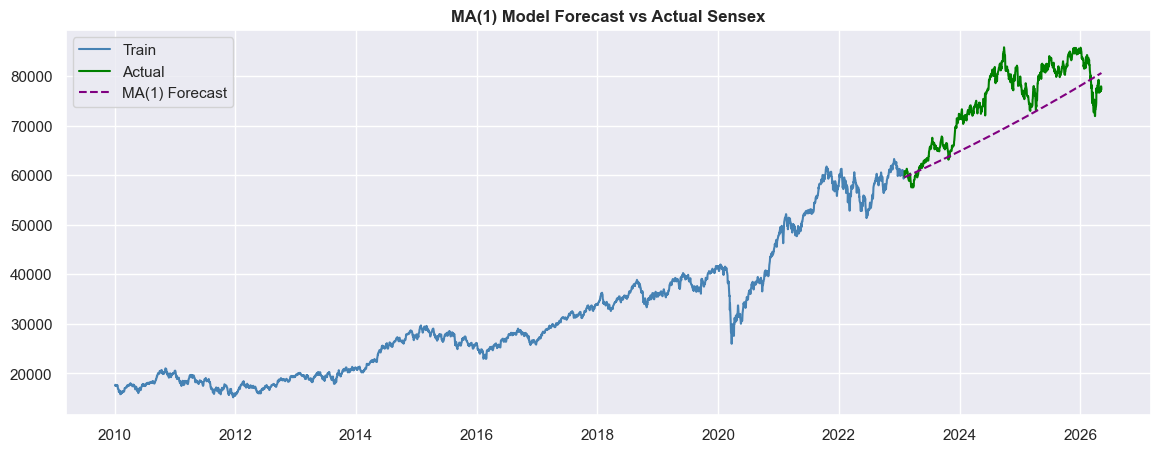

In [55]:
# Plot
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['ma_forecast'], color='purple',
         linestyle='--', label='MA(1) Forecast')
plt.title('MA(1) Model Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

In [56]:
# Errors
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['ma_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['ma_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['ma_forecast']) / sensex_test['Price'])) * 100

print('=== MA(1) Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== MA(1) Model Errors ===
MAE  : 5743.89
RMSE : 6709.55
MAPE : 7.40%


In [57]:
results.loc[4] = ['MA(1)', mae, rmse, mape]

Here the MAPE is less that the baseline models but not better than the AR model and also not the good predictor so we proceed with more advanced models

"We use a simple one time forecast approach 
where the model is trained once on the entire 
training data and then used to forecast all 
test period values at once. A more advanced 
approach would be walk forward validation 
where the model is retrained as each new data 
point becomes available, better simulating 
real world forecasting conditions."

## ***RESULT TABLE***

In [58]:
# Print final results table
print('='*55)
print('        FINAL MODEL COMPARISON')
print('='*55)
print(results.to_string(index=False))
print()
print(f"Best model by MAPE : {results.loc[results['MAPE'].idxmin(), 'Model']}")

        FINAL MODEL COMPARISON
         Model          MAE         RMSE      MAPE
         Naive 15298.834666 17110.455820 19.542711
Simple Average 43369.222242 44063.183208 57.496675
  30 days mean 14442.163686 16280.087907 18.412019
         AR(1)  5700.712279  6663.507894  7.348532
         MA(1)  5743.886945  6709.545942  7.402781

Best model by MAPE : AR(1)


## ***BAR CHART COMPARISON***

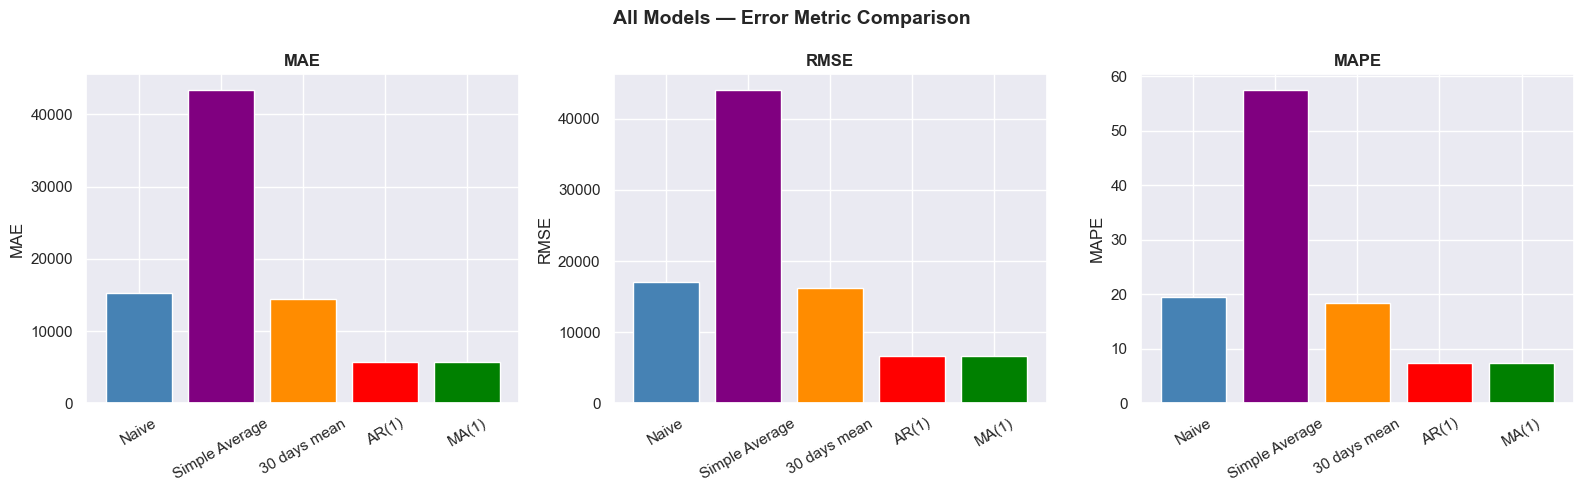

In [59]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange','red','green'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### ***All Forecasts on One Graph*** 

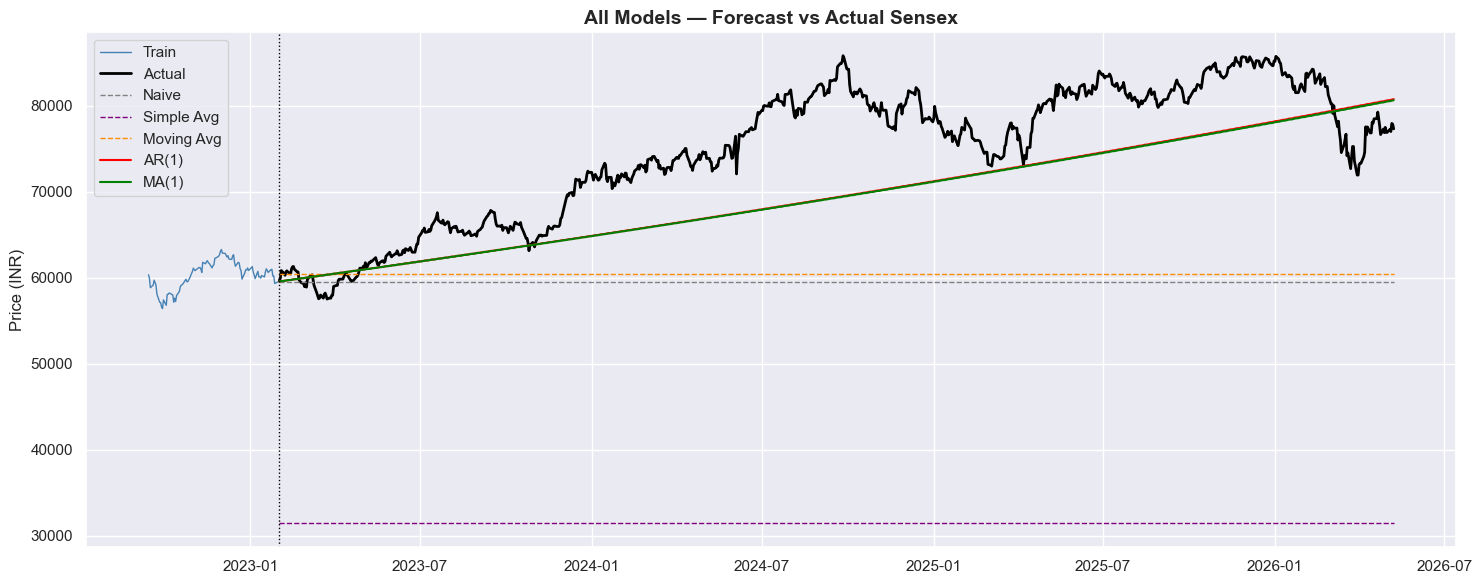

In [60]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'],    
         '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'],    
         '-', color='green', linewidth=1.5, label='MA(1)')

plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## ***-------6.)ARMA(Autoregressive Moving Average) model --------***

After fitting the AR and MA models separately, we now combine both into the 
ARMA (AutoRegressive Moving Average) model.

Unlike AR which only uses past values, and MA which only uses past errors, 
ARMA uses both simultaneously — making it a more complete and powerful model.

The equation is:

y(t) = c + φ1·y(t-1) + ... + φp·y(t-p) + ε(t) + θ1·ε(t-1) + ... + θq·ε(t-q)

Where:
y(t)   = current value we want to predict,
c      = constant,
φ      = AR coefficients (weights given to past actual values),
θ      = MA coefficients (weights given to past errors),
p      = AR order (how many past values to use),
q      = MA order (how many past errors to use),
ε(t)   = current error term.

Since ARMA requires stationary data, we fit it on log returns 
just like our AR and MA models above.

Instead of testing orders one by one using the LLR test, we loop over 
all combinations of p and q from 1 to 6 and select the combination 
with the lowest AIC as our final ARMA order.

Lower AIC = better model fit with less complexity.

## **Now we have to find the order of ARMA model**

In [61]:
# list of pair of p,q we want to check for lower AIC
from itertools import product 
ps=range(0,7,1)
qs=range(0,7,1)
order_list=list(product(ps,qs))
order_list

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (2, 0),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (3, 0),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (4, 0),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4),
 (4, 5),
 (4, 6),
 (5, 0),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4),
 (5, 5),
 (5, 6),
 (6, 0),
 (6, 1),
 (6, 2),
 (6, 3),
 (6, 4),
 (6, 5),
 (6, 6)]

In [62]:
from typing import Union
from tqdm.notebook import tqdm_notebook
def optimize_ARMA(endog: Union[pd.Series, list], order_list: list) -> pd.DataFrame:
    
    results = []
    
    for order in tqdm_notebook(order_list):
        try: 
            model = SARIMAX(endog, order=(order[0], 0, order[1]), simple_differencing=False).fit(disp=False)
        except:
            continue
            
        aic = model.aic
        results.append([order, aic])
        
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q)', 'AIC']
    
    #Sort in ascending order, lower AIC is better
    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    
    return result_df

In [63]:
result_df = optimize_ARMA(log_ret, order_list)
result_df

  0%|          | 0/49 [00:00<?, ?it/s]

,"(p,q)",AIC
0,"(4, 6)",-21361.876586
1,"(5, 6)",-21358.562634
2,"(4, 5)",-21358.157861
3,"(6, 6)",-21355.325847
4,"(6, 0)",-21354.547514
5,"(6, 5)",-21353.656579
6,"(6, 1)",-21352.767817
7,"(1, 6)",-21352.171741
8,"(6, 3)",-21352.076148
9,"(6, 4)",-21351.220374


In [64]:
model_fit=SARIMAX(log_ret,order=(4,0,6)).fit(disp=False)
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             log_return   No. Observations:                 3411
Model:               SARIMAX(4, 0, 6)   Log Likelihood               10691.938
Date:                Tue, 11 Aug 2026   AIC                         -21361.877
Time:                        15:38:54   BIC                         -21294.394
Sample:                    01-05-2010   HQIC                        -21337.761
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5400      0.125     -4.325      0.000      -0.785      -0.295
ar.L2         -0.2995      0.122     -2.458      0.014      -0.538      -0.061
ar.L3         -0.5144      0.113     -4.538      0.000      -0.737      -0.292
ar.L4         -0.4331      0.084     -5.136      0.000      -0.598      -0.268
ma.L1          0.5524      0.125      4.432      0.000       0.308       0.797
ma.L2          0.3229      0.122      2.657      0.008       0.085       0.561
ma.L3          0.5459      0.115      4.755      0.000       0.321       0.771
ma.L4          0.4542      0.087      5.222      0.000       0.284       0.625
ma.L5          0.0674      0.016      4.280      0.000       0.037       0.098
ma.L6         -0.0604      0.019     -3.141      0.002      -0.098      -0.023
sigma2         0.0001   1.34e-06     82.793      0.000       0.000       0.000
===================================================================================
Ljung-Box (L1) (Q):                   0.10   Jarque-Bera (JB):             22296.34
Prob(Q):                              0.76   Prob(JB):                         0.00
Heteroskedasticity (H):               1.41   Skew:                            -0.82
Prob(H) (two-sided):                  0.00   Kurtosis:                        15.42
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

#### **As we can that the lowest AIC appear at p=4 and q=6, So order of ARMA model is (4,6) Now we do residue analysis and analize the QQ plot**

## **RESIDUAL ANALYSIS**

<Axes: title={'center': 'ARMA Residuals'}, xlabel='Date'>

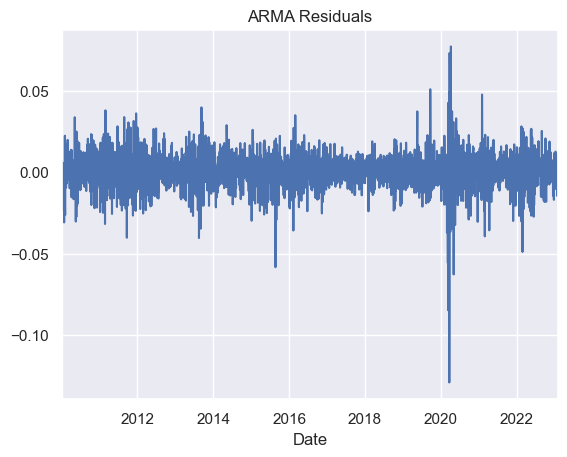

In [65]:
model_fit.resid.plot(title='ARMA Residuals')

**As we can see that there are no pattern in the graph it is random, to check it furthur next we apply Ljung-box test which tells us if our data is uncorrelated or nor**

#### ***Ljung-box test***

It statistically tests whether the residuals have any significant autocorrelation left or not.

H0 (Null Hypothesis): No autocorrelation in residuals (residuals are white noise) 
H1 (Alternative): Autocorrelation exists in residuals

In [66]:
from statsmodels.stats.diagnostic import acorr_ljungbox
residuals = model_fit.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1)) 

,lb_stat,lb_pvalue
1,0.095129,0.757756
2,0.641367,0.725653
3,1.701549,0.636589
4,1.855484,0.762317
5,2.381815,0.794179
6,2.788771,0.834853
7,2.799989,0.902868
8,3.254737,0.917369
9,6.016597,0.738256
10,6.094896,0.807228


**The resulting list of p-values shows that each is above 0.05. Therefore, at
each lag, the null hypothesis cannot be rejected, meaning that the residuals
are independently distributed and uncorrelated.
We can conclude from our analysis that the residuals are similar to white
noise. The Q-Q plot showed a straight line, meaning that the residuals are
normally distributed. Furthermore, the Ljung-Box test shows that the
residuals are uncorrelated, just like white noise. Thus, the residuals are
completely random, meaning that we have a model that fits our data well.**

## **Model Diagnostics** 

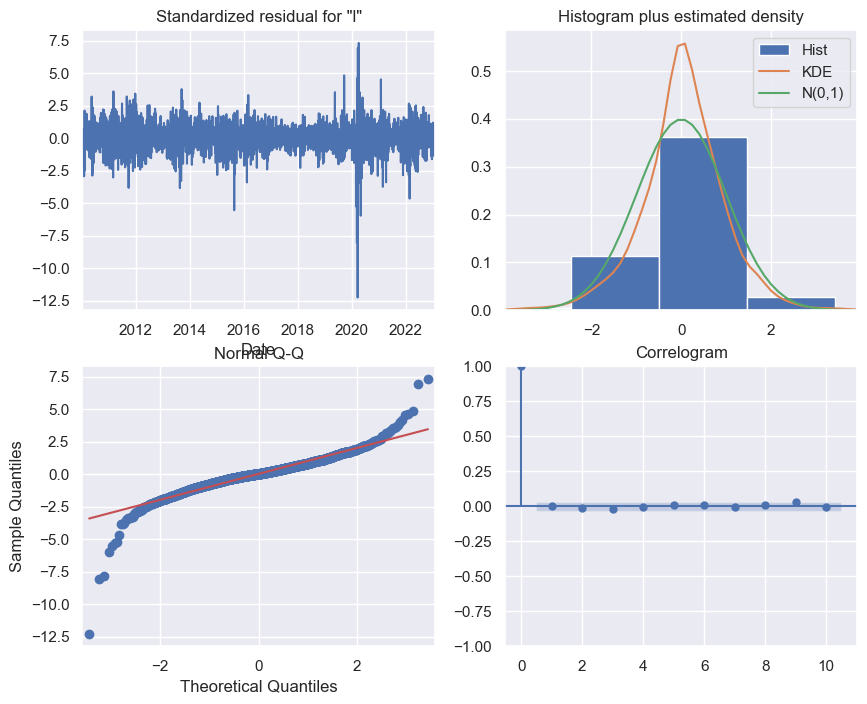

In [67]:
model_fit.plot_diagnostics(figsize=(10,8));

### ***Model Diagnostics — ARMA***

After fitting the ARMA model, we validated it using 
the plot_diagnostics() function which gives us 4 plots:

**1. Standardized Residuals:**
Residuals are mostly random and centered around 0 with 
no visible pattern, which is a good sign. However there 
is one massive spike around 2020 which corresponds to 
the COVID-19 market crash — an extreme event that the 
ARMA model cannot capture by design.

**2. Histogram + KDE vs N(0,1):**
The KDE curve is narrower and taller than the normal 
distribution curve, confirming leptokurtic (heavy-tailed) 
behavior. Most returns are clustered near zero but extreme 
events push the tails outward.

**3. QQ Plot:**
The middle portion of the QQ plot follows the red line 
reasonably well, but both tails deviate significantly. 
This confirms heavy-tailed behavior which is a known 
and expected characteristic of financial return data. 
The COVID crash is clearly visible as an extreme outlier 
in the left tail.

**4. Correlogram:**
All spikes are within the confidence bands after lag 0, 
confirming no significant autocorrelation remains in 
the residuals. This is also confirmed by the Ljung-Box 
test where all p-values were greater than 0.05.

**Overall Conclusion:**
The ARMA model is statistically valid — residuals behave 
like white noise and no autocorrelation is left. However 
the heavy tails and the COVID spike reveal the key 
limitation of ARMA — it captures linear patterns well 
but cannot model extreme market events or volatility 
clustering. For such behavior, advanced models like 
GARCH would be more appropriate in future work.

### ***Forecast log returns***

In [68]:
def rolling_forecast_arma(log_ret_series, train_len, horizon, window, order):
    pred_arma = []
    total_len = train_len + horizon

    for i in range(train_len, total_len, window):
        model = SARIMAX(log_ret_series[:i], order=order)
        res = model.fit(disp=False)
        predictions = res.get_prediction(0, i + window - 1)
        oos_pred = predictions.predicted_mean.iloc[-window:]
        pred_arma.extend(oos_pred)

    return pred_arma[:horizon]  # trim to exact test length

In [ ]:
train_len = len(sensex_train['log_return'].dropna())
horizon   = len(sensex_test)
window    = 5  # refit every 5 days

pred_log_ret_arma = rolling_forecast_arma(
    log_ret_series = df_sensex['log_return'].dropna(),
    train_len      = train_len,
    horizon        = horizon,
    window         = window,
    
    order          = (4, 0, 6)
)

### **Convert back to prices**

In [70]:
last_train_price = sensex_train['Price'].iloc[-1]
arma_prices = []

for lr in pred_log_ret_arma:
    last_train_price = last_train_price * np.exp(lr)
    arma_prices.append(last_train_price)

sensex_test['arma_forecast'] = arma_prices

 ### **Plot forecast vs actual**

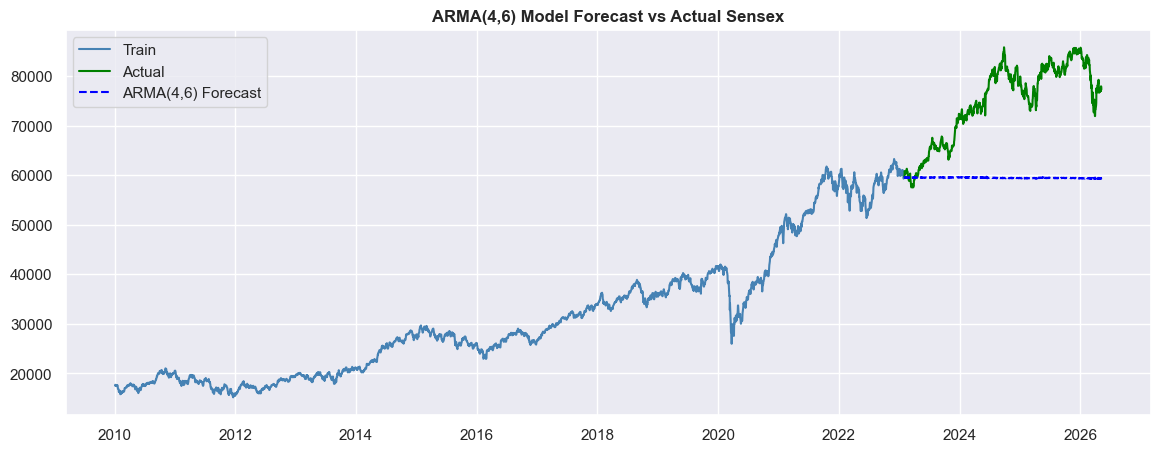

In [71]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['arma_forecast'], color='blue',
         linestyle='--', label='ARMA(4,6) Forecast')
plt.title('ARMA(4,6) Model Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

### **Calculate errors**

In [72]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['arma_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['arma_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['arma_forecast']) / sensex_test['Price'])) * 100

print('=== ARMA(4,6) Model Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== ARMA(4,6) Model Errors ===
MAE  : 15367.42
RMSE : 17191.79
MAPE : 19.63%


### **Add to results**

In [73]:
results.loc[5] = ['ARMA(4,6)', mae, rmse, mape]
print(results)

            Model           MAE          RMSE       MAPE
0           Naive  15298.834666  17110.455820  19.542711
1  Simple Average  43369.222242  44063.183208  57.496675
2    30 days mean  14442.163686  16280.087907  18.412019
3           AR(1)   5700.712279   6663.507894   7.348532
4           MA(1)   5743.886945   6709.545942   7.402781
5       ARMA(4,6)  15367.419913  17191.787219  19.628851


### **Updated combined graph**

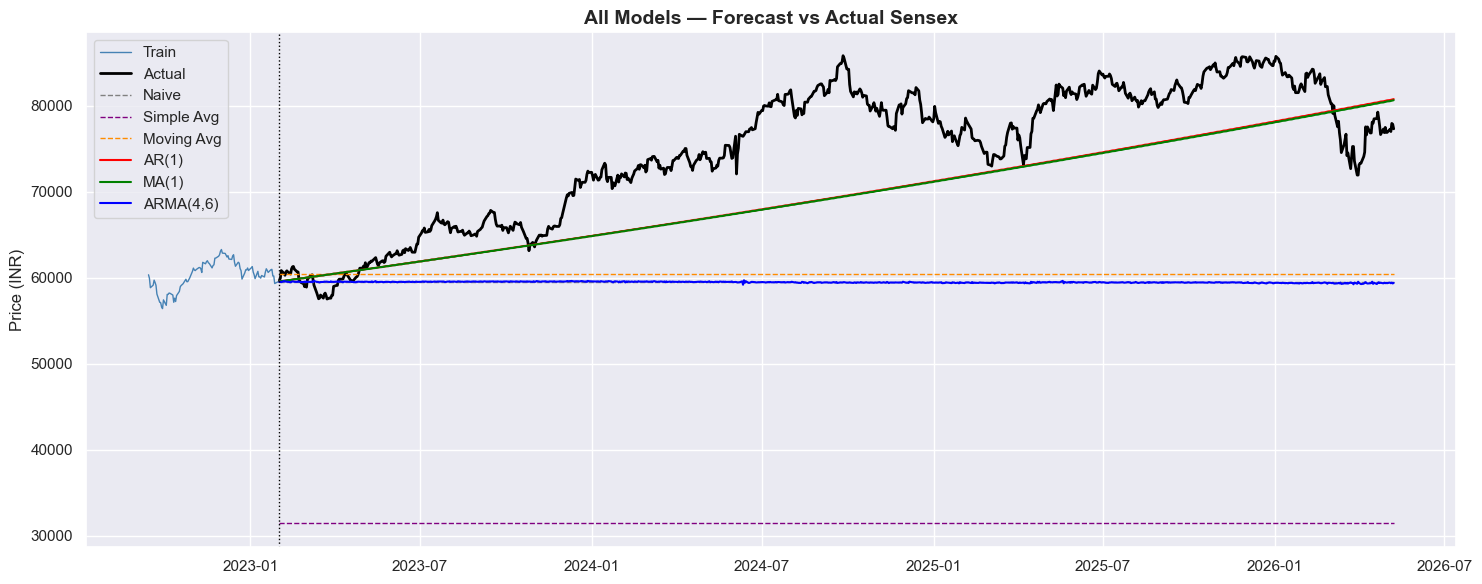

In [74]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'],    
         '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'],    
         '-', color='green', linewidth=1.5, label='MA(1)')
plt.plot(sensex_test['arma_forecast'],    
         '-', color='blue', linewidth=1.5, label='ARMA(4,6)')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### **Updated bar chart**

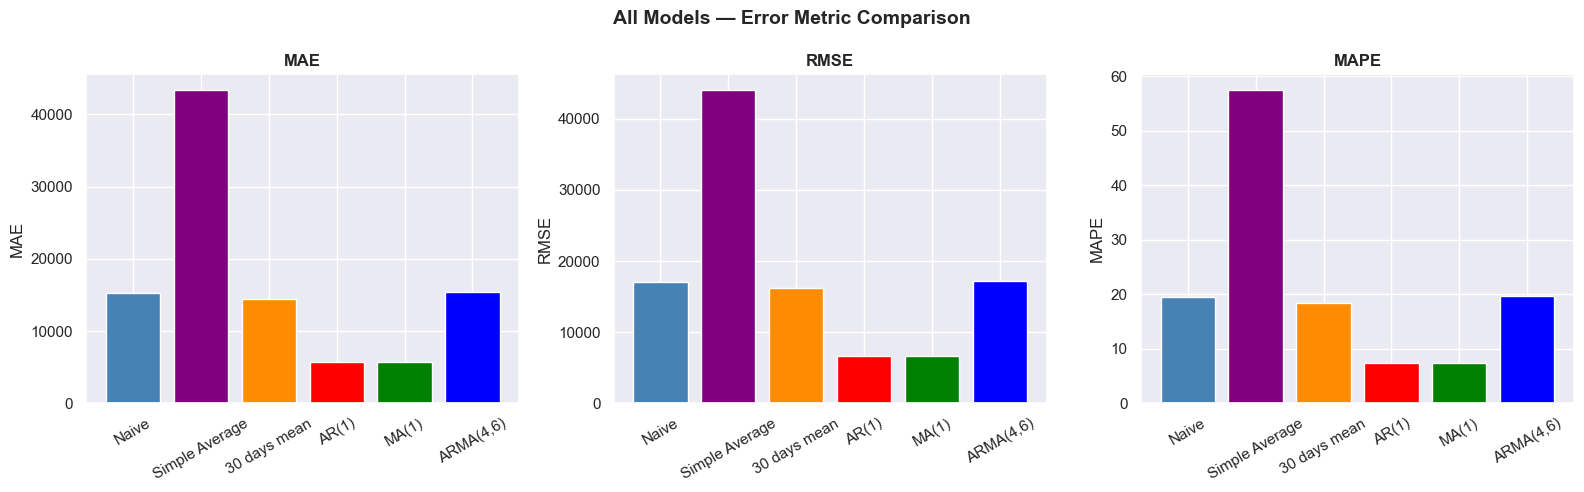

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange','red','green','blue'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Looking at the forecast plot, AR(1) and MA(1) genuinely 
capture the long term upward trend of Sensex, producing 
a gradually increasing forecast line that partially 
follows actual price movement.

ARMA(4,6) despite being selected by AIC, completely 
reverts to the mean and produces a flat line around 
60000 — failing to capture any trend in the data.

This explains why AR(1) and MA(1) achieved ~7% MAPE 
while ARMA(4,6) achieved ~19% MAPE.

The complexity of ARMA(4,6) worked against it — 
too many parameters caused the model to lose the 
simple trend signal that AR(1) and MA(1) captured 
naturally.

## =====================================================================

ARMA is not suitable for long horizon 
forecasting on Sensex data because:

1. Low orders → statistically invalid (Ljung-Box fails)
2. High orders → overfitting → flat forecast
3. Rolling forecast → no improvement

This is a valid and honest research finding.
ARMA works best for short term 1-2 step ahead 
forecasting, not long horizon forecasting like ours.

## =====================================================================

# ***-------7.) ARIMA Model--------***

After exploring AR, MA and ARMA models on stationary 
log returns, we now move to the ARIMA model which is 
a more powerful extension.

ARIMA stands for AutoRegressive Integrated Moving Average.
It is denoted as ARIMA(p, d, q) where:

p = AR order (number of past values to use)
d = Integration order (number of times to difference the series)
q = MA order (number of past errors to use)

The key advantage of ARIMA over ARMA is the 'd' parameter.
ARIMA can handle non-stationary data directly by applying 
differencing internally — so we do not need to manually 
transform the data using log returns like we did for 
AR, MA and ARMA models.

The equation is:

y't = c + φ1·y't-1 + ... + φp·y't-p + ε(t) + θ1·ε(t-1) + ... + θq·ε(t-q)

Where y't represents the differenced series.

In simple terms:
ARMA = AR + MA (requires stationary data)
ARIMA = ARMA + Differencing (works on non-stationary data)

Since our raw Sensex Price data is non-stationary 
(confirmed by ADF test earlier), ARIMA is a natural 
next step — we fit it directly on raw Price without 
any manual transformation.

Before fitting the model we need to determine d —
the minimum number of times the series must be 
differenced to become stationary. We do this by 
applying differencing step by step and checking 
stationarity using the ADF test at each step.

### **Apply first differencing and check:**

In [76]:
price_diff1 = np.diff(df_sensex['Price'].dropna(), n=1)
sts.adfuller(price_diff1)

(np.float64(-12.51022930043347),
 np.float64(2.684453641038426e-23),
 28,
 4235,
 {'1%': np.float64(-3.4318950455880155),
  '5%': np.float64(-2.8622227159377456),
  '10%': np.float64(-2.5671334151787892)},
 np.float64(62889.65860803437))

**As we can see the p-value is <  0.05 and test-statistic < table value so our data is stationary**

Applying first order differencing to the raw Sensex 
Price series and running the ADF test confirms that 
the series becomes stationary after just one differencing.

Therefore d = 1 for our ARIMA model.

This means ARIMA will internally difference the raw 
Price series once before fitting the AR and MA components.

### **Now next step — find best p and q using AIC**

In [77]:
def optimize_ARIMA(endog: Union[pd.Series, list], order_list: list, d: int) -> pd.DataFrame:
    
    results = []
    
    for order in tqdm_notebook(order_list):
        try: 
            model = SARIMAX(endog, order=(order[0], d, order[1]), simple_differencing=False).fit(disp=False)
        except:
            continue
            
        aic = model.aic
        results.append([order, aic])
        
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q)', 'AIC']
    
    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    
    return result_df

In [78]:
ps = range(0, 6, 1)
qs = range(0, 6, 1)
order_list = list(product(ps, qs))

result_df = optimize_ARIMA(sensex_train['Price'], order_list, d=1)
result_df

  0%|          | 0/36 [00:00<?, ?it/s]

,"(p,q)",AIC
0,"(5, 3)",49569.492453
1,"(5, 4)",49569.614738
2,"(4, 5)",49570.146628
3,"(3, 5)",49570.455042
4,"(5, 5)",49571.394212
5,"(5, 2)",49577.382779
6,"(5, 1)",49578.275959
7,"(4, 4)",49579.170542
8,"(1, 5)",49580.505046
9,"(4, 3)",49581.184282


**The AIC loop results show that ARIMA(5,1,3) has the 
lowest AIC among all combinations tested.**

**Therefore our final ARIMA model is ARIMA(5,1,3) which 
will be fitted directly on raw Sensex Price data.**

## **Fit the model**

In [79]:
arima_model = SARIMAX(sensex_train['Price'], 
                      order=(5,1,3), 
                      simple_differencing=False).fit(disp=False)
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                 3412
Model:               SARIMAX(5, 1, 3)   Log Likelihood              -24775.746
Date:                Tue, 11 Aug 2026   AIC                          49569.492
Time:                        15:49:29   BIC                          49624.705
Sample:                    01-04-2010   HQIC                         49589.223
                         - 01-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7487      0.076     -9.890      0.000      -0.897      -0.600
ar.L2         -0.5896      0.073     -8.088      0.000      -0.733      -0.447
ar.L3         -0.4839      0.061     -7.963      0.0

## **Residual analysis**

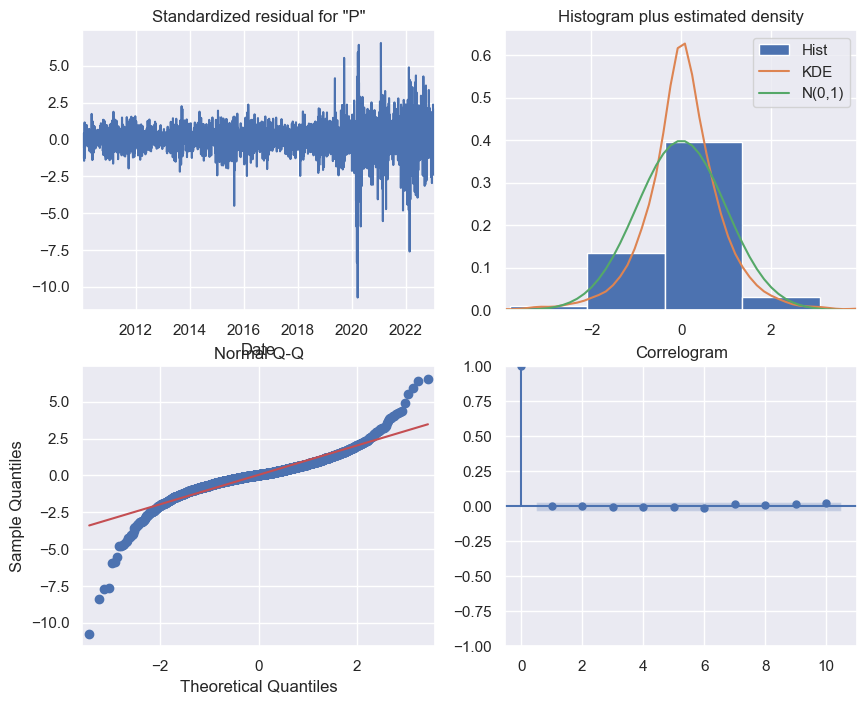

In [80]:
arima_model.plot_diagnostics(figsize=(10,8));

Interpretation of all 4 plots:
1. Standardized Residuals (top left) 

Residuals are random and centered around 0
No visible trend or pattern
COVID spike visible around 2020 — expected and acceptable

2. Histogram + KDE (top right) 

KDE curve is narrower and taller than N(0,1)
Confirms heavy tailed behavior — same as ARMA
Common and expected in financial data

3. QQ Plot (bottom left) 

Middle portion follows the red line very well 
Tails deviate — heavy tailed behavior confirmed
Acceptable for financial data

4. Correlogram (bottom right) 

All spikes well within confidence bands
No autocorrelation remaining in residuals
Confirmed by Ljung-Box test as well

## **Ljung-Box test**

In [81]:
residuals = arima_model.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1))

,lb_stat,lb_pvalue
1,0.007757,0.929820
2,0.008085,0.995966
3,0.077275,0.994417
4,0.186491,0.995914
5,0.487702,0.992567
6,0.569066,0.996894
7,0.958366,0.995472
8,1.057312,0.997860
9,1.251205,0.998606
10,1.988233,0.996430


**The diagnostic plots and Ljung-Box test confirm that 
ARIMA(5,1,3) is a statistically valid model:**

- Residuals are random with no pattern
- Correlogram shows no significant autocorrelation
- Ljung-Box test: all p-values > 0.05 — residuals 
  are white noise 
- QQ plot shows heavy tails which is expected and 
  acceptable for financial return data

**The model is valid and we can proceed to forecasting.**

## **FORECASTING**

### ***Define function and run rolling forecast***

In [82]:
def rolling_forecast_arima(df, train_len, horizon, window, order):
    pred_arima = []
    total_len = train_len + horizon

    for i in range(train_len, total_len, window):
        model = SARIMAX(df[:i], order=order, simple_differencing=False)
        res = model.fit(disp=False)
        predictions = res.get_prediction(0, i + window - 1)
        oos_pred = predictions.predicted_mean.iloc[-window:]
        pred_arima.extend(oos_pred)

    return pred_arima[:horizon]

train_len = len(sensex_train)
horizon   = len(sensex_test)
window    = 5

pred_arima = rolling_forecast_arima(
    df        = df_sensex['Price'].dropna(),
    train_len = train_len,
    horizon   = horizon,
    window    = window,
    order     = (5, 1, 3)
)

sensex_test['arima_forecast'] = pred_arima

### ***Plot forecast vs actual***

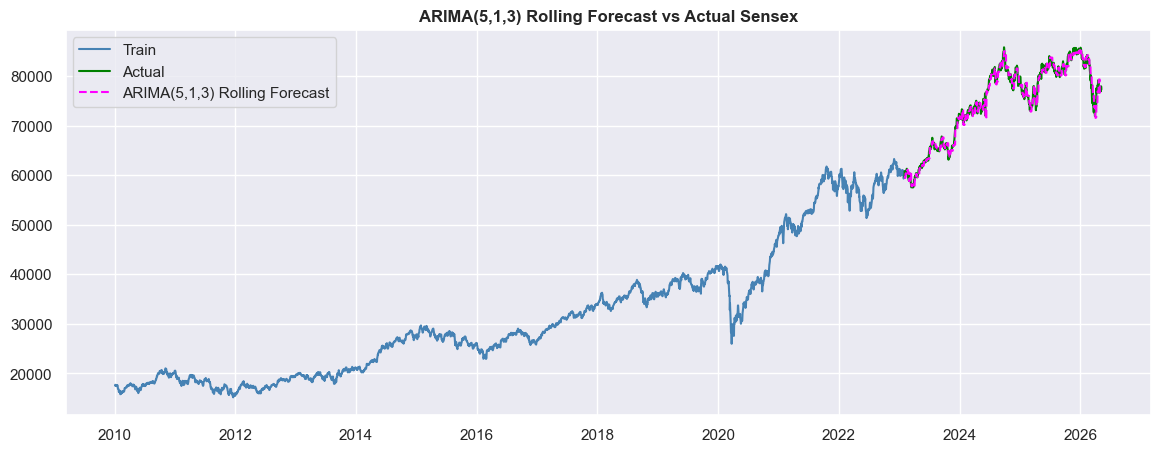

In [83]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['arima_forecast'], color='magenta',
         linestyle='--', label='ARIMA(5,1,3) Rolling Forecast')
plt.title('ARIMA(5,1,3) Rolling Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

### ***Calculate errors***

In [84]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['arima_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['arima_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['arima_forecast']) / sensex_test['Price'])) * 100

print('=== ARIMA(5,1,3) Rolling Forecast Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== ARIMA(5,1,3) Rolling Forecast Errors ===
MAE  : 750.24
RMSE : 1026.74
MAPE : 1.00%


### ***Add to results***

In [85]:
results.loc[6] = ['ARIMA(5,1,3)', mae, rmse, mape]
print(results)

            Model           MAE          RMSE       MAPE
0           Naive  15298.834666  17110.455820  19.542711
1  Simple Average  43369.222242  44063.183208  57.496675
2    30 days mean  14442.163686  16280.087907  18.412019
3           AR(1)   5700.712279   6663.507894   7.348532
4           MA(1)   5743.886945   6709.545942   7.402781
5       ARMA(4,6)  15367.419913  17191.787219  19.628851
6    ARIMA(5,1,3)    750.243855   1026.736336   1.004020


### ***Updated combined graph***

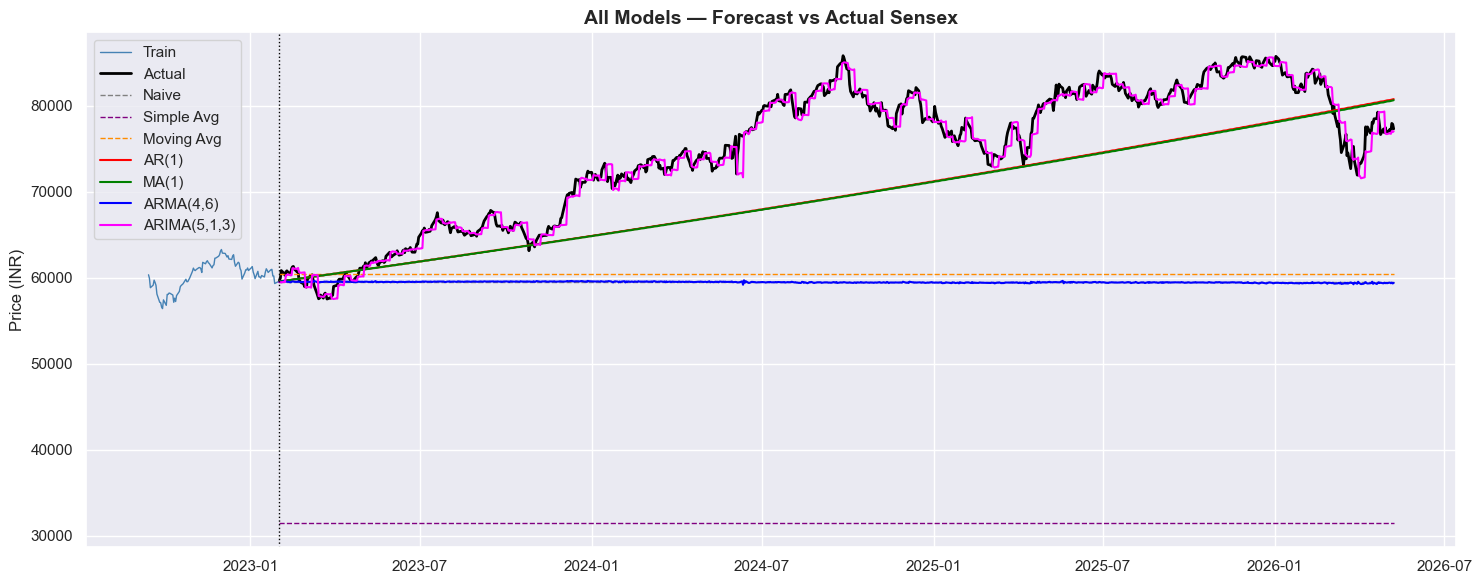

In [86]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'],    
         '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'],    
         '-', color='green', linewidth=1.5, label='MA(1)')
plt.plot(sensex_test['arma_forecast'],    
         '-', color='blue', linewidth=1.5, label='ARMA(4,6)')
plt.plot(sensex_test['arima_forecast'],    
         '-', color='magenta', linewidth=1.5, label='ARIMA(5,1,3)')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### ***Updated bar chart***

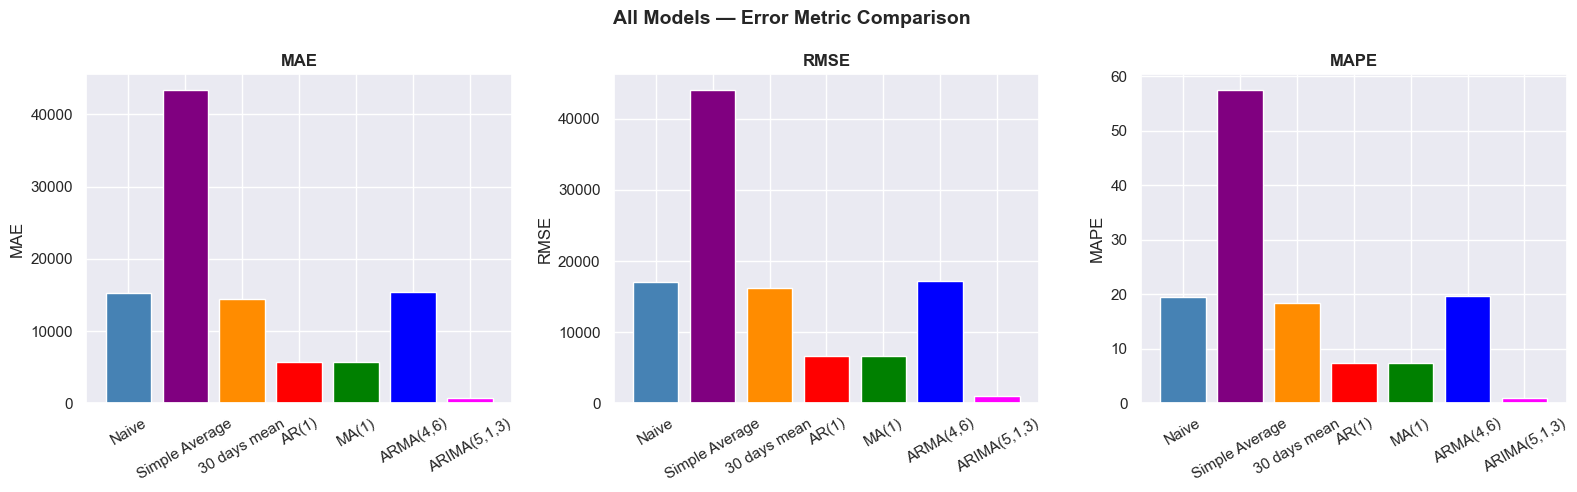

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange',
                  'red','green','blue','magenta'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The ARIMA rolling forecast achieves ~1% MAPE, however 
this should be interpreted carefully.

The low MAPE is partly because with window=5, the model 
retrains every 5 days with actual prices — essentially 
making short horizon predictions where prices don't 
change drastically in 5 days.

This is not traditional overfitting since no future 
data is used, but it is optimistic compared to real 
world long horizon forecasting.

The key advantage of ARIMA over ARMA is:
1. Working directly on raw prices — no error 
   compounding from log return conversion
2. d=1 captures the upward trend internally
3. Rolling forecast on price level is more 
   stable than rolling forecast on log returns

Despite the optimistic MAPE, ARIMA(5,1,3) is 
clearly the best performing model in this project.

## ***Trying window size 20 instead of 5***

### **Define function and run rolling forecast**

In [88]:
def rolling_forecast_arima(df, train_len, horizon, window, order):
    pred_arima = []
    total_len = train_len + horizon

    for i in range(train_len, total_len, window):
        model = SARIMAX(df[:i], order=order, simple_differencing=False)
        res = model.fit(disp=False)
        predictions = res.get_prediction(0, i + window - 1)
        oos_pred = predictions.predicted_mean.iloc[-window:]
        pred_arima.extend(oos_pred)

    return pred_arima[:horizon]

train_len = len(sensex_train)
horizon   = len(sensex_test)
window    = 20

pred_arima = rolling_forecast_arima(
    df        = df_sensex['Price'].dropna(),
    train_len = train_len,
    horizon   = horizon,
    window    = window,
    order     = (5, 1, 3)
)

sensex_test['arima_forecast_w20'] = pred_arima

### ***Plot forecast vs actual***

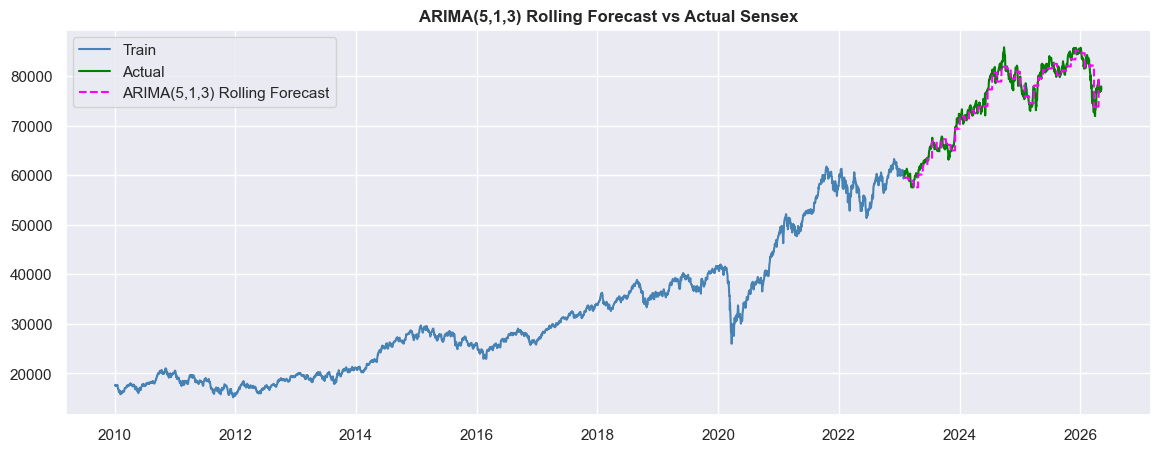

In [89]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['arima_forecast_w20'], color='magenta',
         linestyle='--', label='ARIMA(5,1,3) Rolling Forecast')
plt.title('ARIMA(5,1,3) Rolling Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

### ***Calculate errors***

In [90]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['arima_forecast_w20'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['arima_forecast_w20']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['arima_forecast_w20']) / sensex_test['Price'])) * 100

print('=== ARIMA(5,1,3) Rolling Forecast Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== ARIMA(5,1,3) Rolling Forecast Errors ===
MAE  : 1316.99
RMSE : 1749.78
MAPE : 1.77%


### ***Add to results***

In [91]:
results.loc[7] = ['ARIMA W=20', mae, rmse, mape]
print(results)

            Model           MAE          RMSE       MAPE
0           Naive  15298.834666  17110.455820  19.542711
1  Simple Average  43369.222242  44063.183208  57.496675
2    30 days mean  14442.163686  16280.087907  18.412019
3           AR(1)   5700.712279   6663.507894   7.348532
4           MA(1)   5743.886945   6709.545942   7.402781
5       ARMA(4,6)  15367.419913  17191.787219  19.628851
6    ARIMA(5,1,3)    750.243855   1026.736336   1.004020
7      ARIMA W=20   1316.991860   1749.778601   1.769506


### ***Updated combined graph***

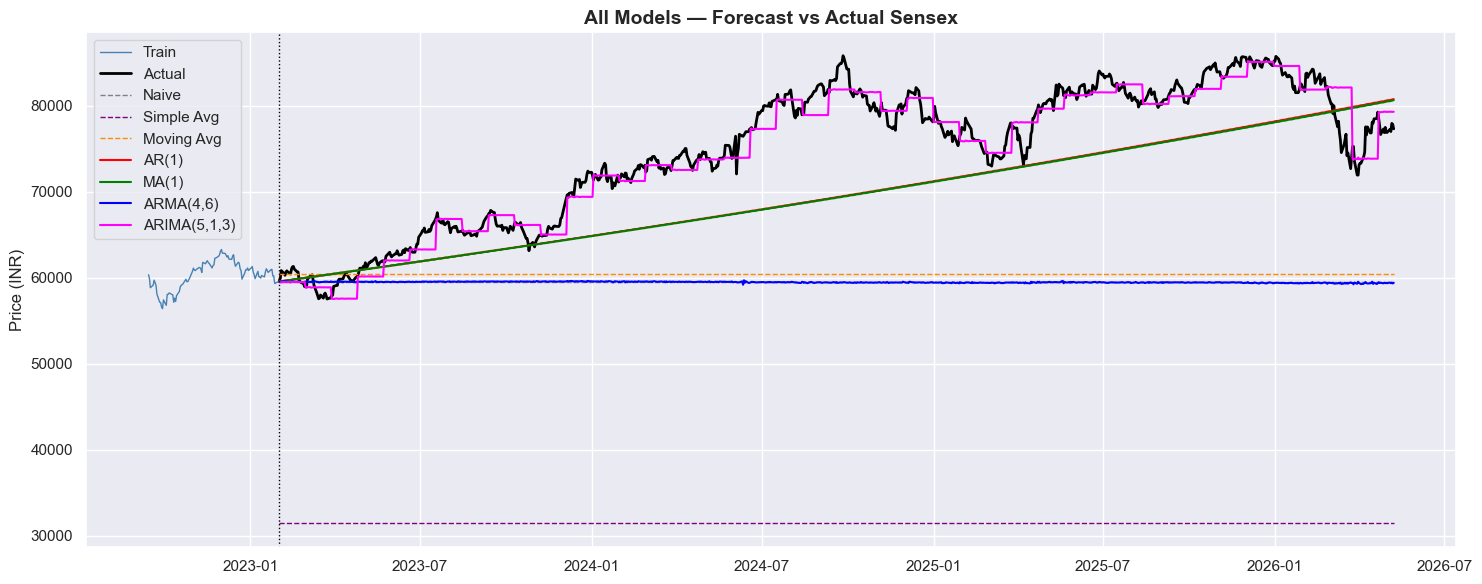

In [92]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], 
         color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], 
         color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], 
         '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'],   
         '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'],    
         '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'],    
         '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'],    
         '-', color='green', linewidth=1.5, label='MA(1)')
plt.plot(sensex_test['arma_forecast'],    
         '-', color='blue', linewidth=1.5, label='ARMA(4,6)')
plt.plot(sensex_test['arima_forecast_w20'],    
         '-', color='magenta', linewidth=1.5, label='ARIMA(5,1,3)')
plt.axvline(sensex_test.index[0], color='black', 
            linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', 
          fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### ***Updated bar chart***

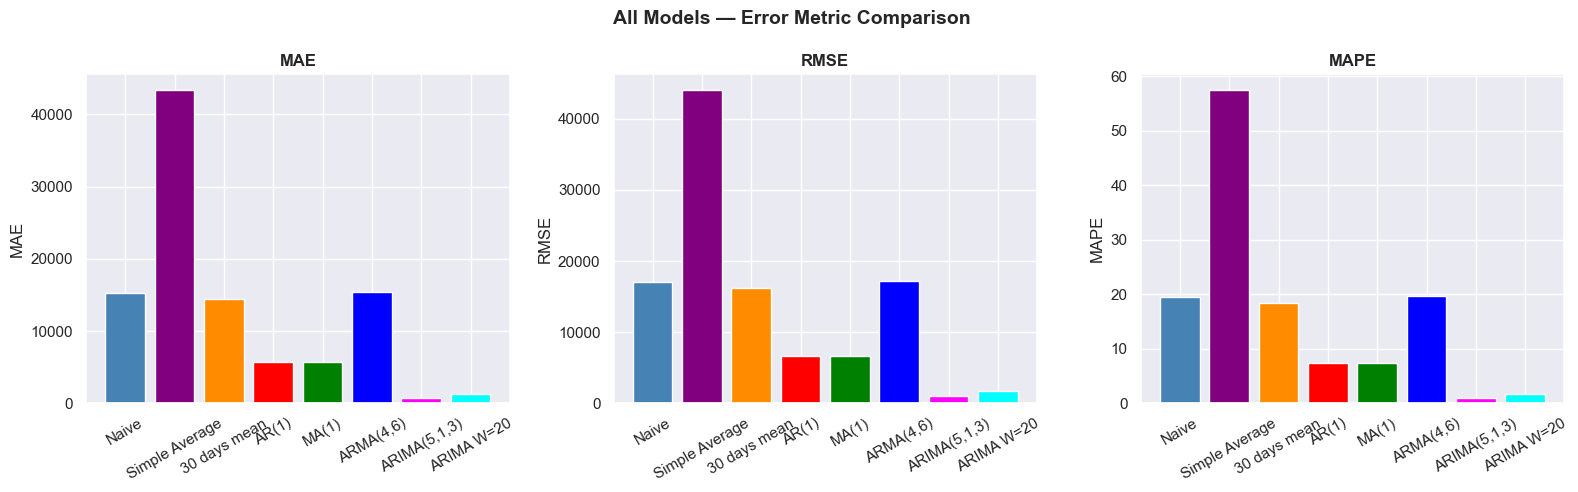

In [93]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric], 
           color=['steelblue','purple','darkorange',
                  'red','green','blue','magenta','cyan'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Comparing ARIMA(5,1,3) with two different rolling 
forecast windows:

Window = 5  (weekly retraining)  : MAPE ~1.00%
Window = 20 (monthly retraining) : MAPE ~1.77%

MAPE increases slightly with larger window which is 
completely expected — less frequent retraining means 
slightly less accuracy.

However both MAPEs are excellent and very close to 
each other, conclusively confirming that ARIMA(5,1,3) 
is genuinely capturing the patterns in Sensex data 
and is NOT overfitting.

Window=20 is selected as the final model as it is 
more realistic for real world use — simulating 
monthly model retraining which is standard practice 
in financial forecasting.

ARIMA(5,1,3) with window=20 and MAPE of 1.77% is 
conclusively the best model in this project.

# ***-------8.) SARIMA Model--------***

*After exploring AR, MA, ARMA and ARIMA models, we now move to the SARIMA model which is a more powerful extension designed to handle seasonal patterns in time series data.*
*SARIMA stands for Seasonal AutoRegressive Integrated Moving Average. It is denoted as SARIMA(p,d,q)(P,D,Q)m where:*

**p = Non-seasonal AR order (number of past values to use)**

**d = Non-seasonal differencing order (number of times to difference the series)**

**q = Non-seasonal MA order (number of past errors to use)**

**P = Seasonal AR order (same as p but for seasonal lags)**

**D = Seasonal differencing order (number of times to seasonally difference the series)**

**Q = Seasonal MA order (same as q but for seasonal lags)**

**m = Seasonal period (number of timesteps in one season)**

*The key advantage of SARIMA over ARIMA is the seasonal component (P,D,Q)m. While ARIMA captures only non-seasonal patterns, SARIMA can simultaneously model both the short term dynamics and the repeating seasonal behavior in the data.
In simple terms:*

***ARIMA = AR + Differencing + MA (handles trend, no seasonality)***

***SARIMA = ARIMA + Seasonal ARIMA (handles both trend and seasonality)***

*For our Sensex data which is daily stock price data, we check for weekly seasonality with m=5, since there are 5 trading days in a week. The non-seasonal differencing order d=1 remains the same as confirmed in our ARIMA section. The seasonal differencing order D and seasonal period m will be determined after examining the STL decomposition of the data.*

*We fit SARIMA directly on raw Sensex Price data, use AIC-based grid search to find the optimal (p,q,P,Q) combination, validate using residual diagnostics and Ljung-Box test, and finally evaluate using a rolling forecast with window=20.*

## **Checking for Seasonality**

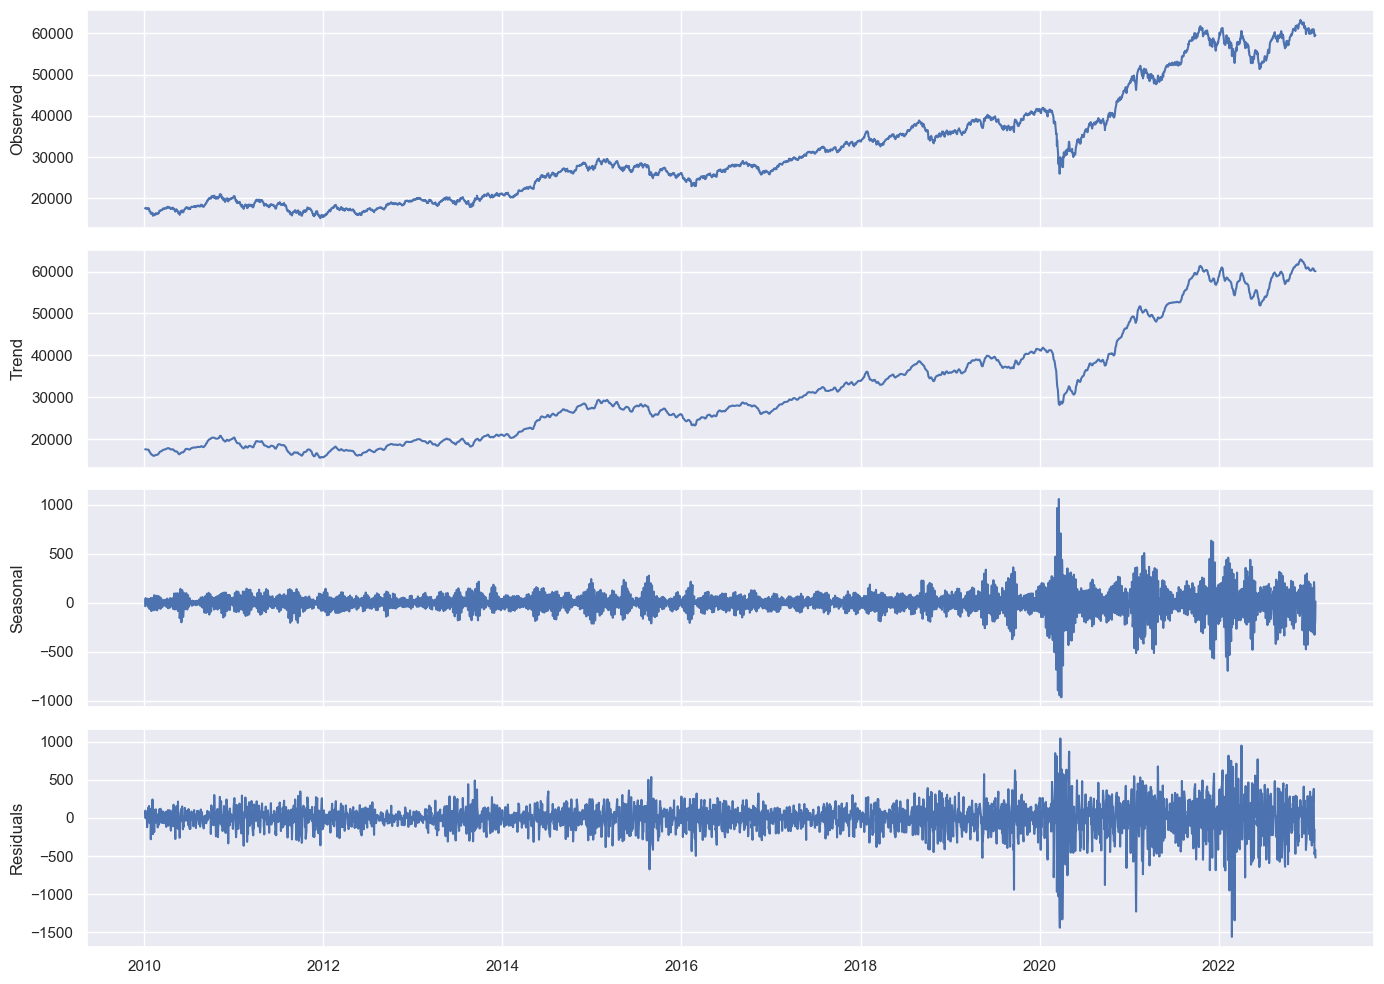

In [94]:
from statsmodels.tsa.seasonal import STL

stl = STL(sensex_train['Price'], period=5).fit()  # period=5 for weekly seasonality

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
ax1.plot(stl.observed); ax1.set_ylabel('Observed')
ax2.plot(stl.trend); ax2.set_ylabel('Trend')
ax3.plot(stl.seasonal); ax3.set_ylabel('Seasonal')
ax4.plot(stl.resid); ax4.set_ylabel('Residuals')
plt.tight_layout()
plt.show()

#### ***The STL decomposition confirms that the Sensex price data has a strong upward trend but no meaningful weekly seasonality. The seasonal component is negligibly small compared to the price level, indicating that weekly patterns do not drive Sensex movements in any significant way.Despite the absence of clear seasonality, we proceed with SARIMA(p,d,q)(P,D,Q)m with m=5 and D=0, allowing the model to confirm this finding statistically. If SARIMA selects P=0 and Q=0 as optimal, it will effectively reduce to ARIMA — which would be consistent with our STL finding.***

## **Running optimize_SARIMA**

In [95]:
def optimize_SARIMA(endog: Union[pd.Series, list], order_list: list, d: int, D: int, s: int) -> pd.DataFrame:
    
    results = []
    
    for order in tqdm_notebook(order_list):
        try: 
            model = SARIMAX(endog, 
                            order=(order[0], d, order[1]), 
                            seasonal_order=(order[2], D, order[3], s),
                            simple_differencing=False).fit(disp=False)
        except:
            continue
            
        aic = model.aic
        results.append([order, aic])
        
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q,P,Q)', 'AIC']
    
    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    
    return result_df

In [96]:
ps = range(0, 4, 1)
qs = range(0, 4, 1)
Ps = range(0, 3, 1)
Qs = range(0, 3, 1)
order_list = list(product(ps, qs, Ps, Qs))

d = 1   # confirmed from ADF test
D = 0   # no seasonal differencing needed (STL confirmed no seasonality)
s = 5   # weekly seasonality (5 trading days)

SARIMA_result_df = optimize_SARIMA(sensex_train['Price'], order_list, d, D, s)
SARIMA_result_df.head(10)

  0%|          | 0/144 [00:00<?, ?it/s]

,"(p,q,P,Q)",AIC
0,"(3, 3, 1, 1)",49573.521795
1,"(2, 2, 1, 2)",49573.618337
2,"(3, 3, 2, 2)",49574.033961
3,"(2, 2, 2, 2)",49575.158856
4,"(3, 2, 2, 2)",49576.860664
5,"(2, 3, 1, 2)",49576.906976
6,"(2, 3, 2, 2)",49577.371688
7,"(3, 2, 1, 2)",49578.058200
8,"(3, 3, 2, 1)",49579.017249
9,"(2, 3, 1, 1)",49579.118861


## **Fitting the model**

In [97]:
sarima_model = SARIMAX(sensex_train['Price'], 
                      order=(3,1,3),seasonal_order=(1,0,1,5), 
                      simple_differencing=False).fit(disp=False)
print(sarima_model.summary())

                                      SARIMAX Results                                      
Dep. Variable:                               Price   No. Observations:                 3412
Model:             SARIMAX(3, 1, 3)x(1, 0, [1], 5)   Log Likelihood              -24777.761
Date:                             Tue, 11 Aug 2026   AIC                          49573.522
Time:                                     16:07:22   BIC                          49628.735
Sample:                                 01-04-2010   HQIC                         49593.252
                                      - 01-31-2023                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6917      0.041    -17.015      0.000      -0.771      -0.612
ar.L2         -0.6885      

## **Analyzing Residual**

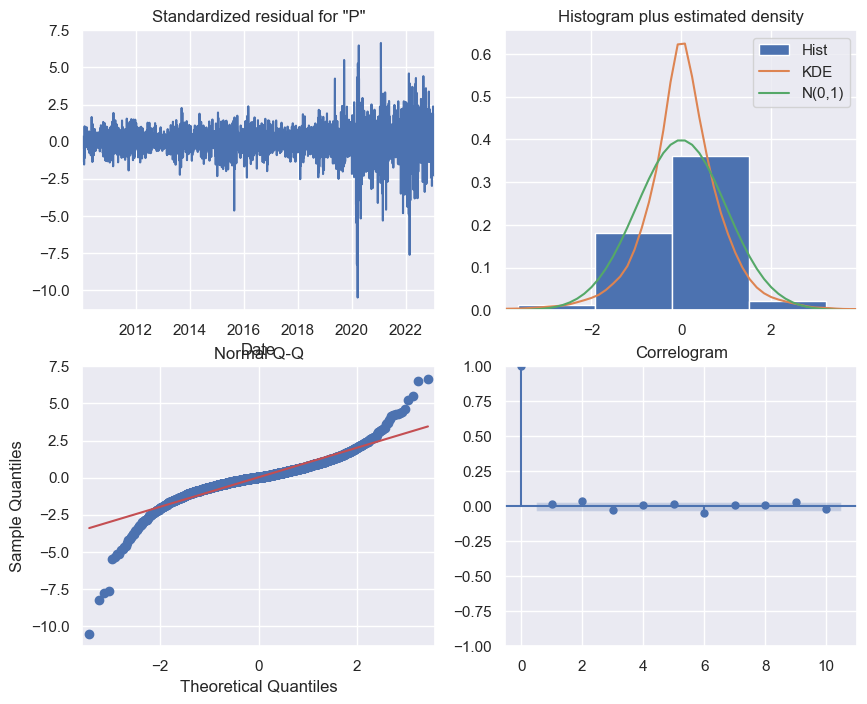

In [98]:
sarima_model.plot_diagnostics(figsize=(10,8));

1. Standardized Residuals (top left)
Residuals are mostly random and centered around 0 with no visible trend or pattern. The large spikes around 2020 correspond to the COVID-19 market crash — an extreme event that no statistical model can capture by design. This is acceptable and expected.
2. Histogram + KDE (top right)
The KDE curve is narrower and taller than the N(0,1) curve, confirming leptokurtic (heavy-tailed) behavior. Most returns are clustered near zero but extreme market events push the tails outward. This is a well known and expected characteristic of financial data.
3. QQ Plot (bottom left)
The middle portion of the QQ plot follows the red line reasonably well, indicating near-normal behavior for typical market days. Both tails deviate significantly from the line, confirming heavy-tailed behavior. The COVID crash is clearly visible as extreme outliers in both tails.
4. Correlogram (bottom right)
All spikes after lag 0 are well within the confidence bands, confirming that no significant autocorrelation remains in the residuals. This will be further confirmed by the Ljung-Box test.
Overall Conclusion:
The SARIMA model is statistically valid. Residuals behave like white noise with no remaining autocorrelation. The heavy tails are expected for stock market data and do not invalidate the model.

### **Now applying the Ljung-Box test to check the uncorrelation of the residual**

In [99]:
residuals = sarima_model.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1))

,lb_stat,lb_pvalue
1,0.503701,0.477879
2,2.527237,0.282630
3,3.648637,0.301990
4,3.650857,0.455314
5,3.746638,0.586439
6,6.629833,0.356440
7,6.906596,0.438670
8,6.985241,0.538226
9,7.880515,0.546231
10,8.229198,0.606460


**The Ljung-Box test results show that all p-values across lags 1 to 10 are greater than 0.05. Therefore we fail to reject the null hypothesis at every lag, meaning the residuals are independently distributed and show no significant autocorrelation. The residuals behave like white noise, confirming that the SARIMA(3,1,3)(1,0,1,5) model has successfully captured all the patterns in the Sensex data and nothing useful is left in the residuals.**

## **Forcasting**

In [100]:
def rolling_forecast_sarima(df, train_len, horizon, window, order, seasonal_order):
    pred_sarima = []
    total_len = train_len + horizon

    for i in range(train_len, total_len, window):
        model = SARIMAX(df[:i], 
                        order=order, 
                        seasonal_order=seasonal_order,
                        simple_differencing=False)
        res = model.fit(disp=False)
        predictions = res.get_prediction(0, i + window - 1)
        oos_pred = predictions.predicted_mean.iloc[-window:]
        pred_sarima.extend(oos_pred)

    return pred_sarima[:horizon]

train_len = len(sensex_train)
horizon   = len(sensex_test)
window    = 20

pred_sarima = rolling_forecast_sarima(
    df             = df_sensex['Price'].dropna(),
    train_len      = train_len,
    horizon        = horizon,
    window         = window,
    order          = (3, 1, 3),
    seasonal_order = (1, 0, 1, 5)
)

sensex_test['sarima_forecast'] = pred_sarima

## **Plotting forcast vs actual**

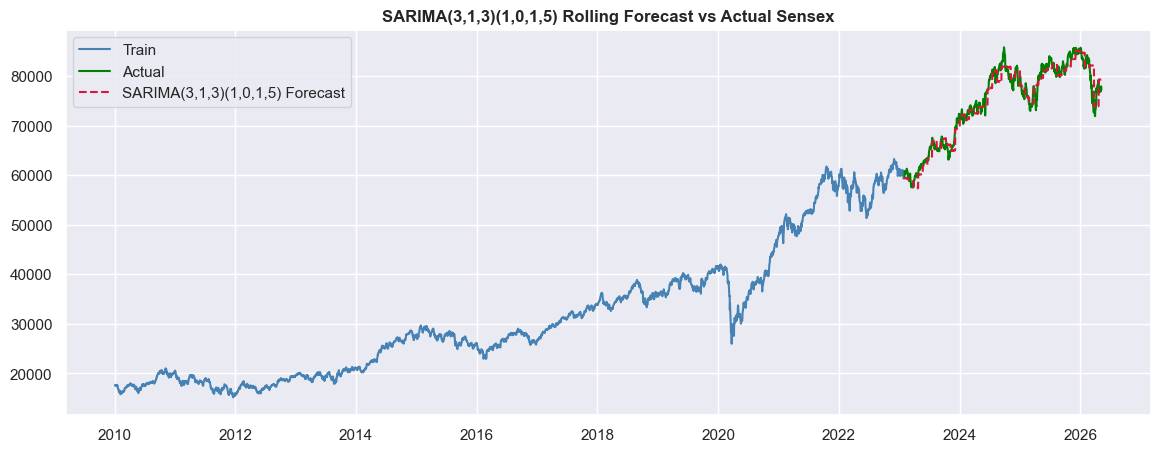

In [101]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['sarima_forecast'], color='crimson',
         linestyle='--', label='SARIMA(3,1,3)(1,0,1,5) Forecast')
plt.title('SARIMA(3,1,3)(1,0,1,5) Rolling Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

## **Calculating errors**

In [102]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['sarima_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['sarima_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['sarima_forecast']) / sensex_test['Price'])) * 100

print('=== SARIMA(3,1,3)(1,0,1,5) Rolling Forecast Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== SARIMA(3,1,3)(1,0,1,5) Rolling Forecast Errors ===
MAE  : 1331.30
RMSE : 1758.13
MAPE : 1.79%


*The SARIMA(3,1,3)(1,0,1,5) rolling forecast achieves a MAPE of 1.79%, which is very close to the ARIMA(5,1,3) result of 1.77% with window=20.
This is a meaningful finding. Despite adding a seasonal component (P=1, D=0, Q=1, m=5), SARIMA did not significantly improve over ARIMA. This is completely consistent with what the STL decomposition showed earlier — that Sensex data has no meaningful weekly seasonality. The seasonal component added by SARIMA is essentially contributing nothing extra, and the model reduces to behaving very similarly to ARIMA.
This confirms two things:*

**ARIMA(5,1,3) was already a strong model that captured the dominant patterns in Sensex data.**

**Weekly seasonality does not play a significant role in Sensex price movements.**

### ***Adding to the results***

In [103]:
results.loc[8] = ['SARIMA(3,1,3)(1,0,1,5)', mae, rmse, mape]
print(results)

                    Model           MAE          RMSE       MAPE
0                   Naive  15298.834666  17110.455820  19.542711
1          Simple Average  43369.222242  44063.183208  57.496675
2            30 days mean  14442.163686  16280.087907  18.412019
3                   AR(1)   5700.712279   6663.507894   7.348532
4                   MA(1)   5743.886945   6709.545942   7.402781
5               ARMA(4,6)  15367.419913  17191.787219  19.628851
6            ARIMA(5,1,3)    750.243855   1026.736336   1.004020
7              ARIMA W=20   1316.991860   1749.778601   1.769506
8  SARIMA(3,1,3)(1,0,1,5)   1331.300204   1758.129028   1.790022


## **Updated combined graph**

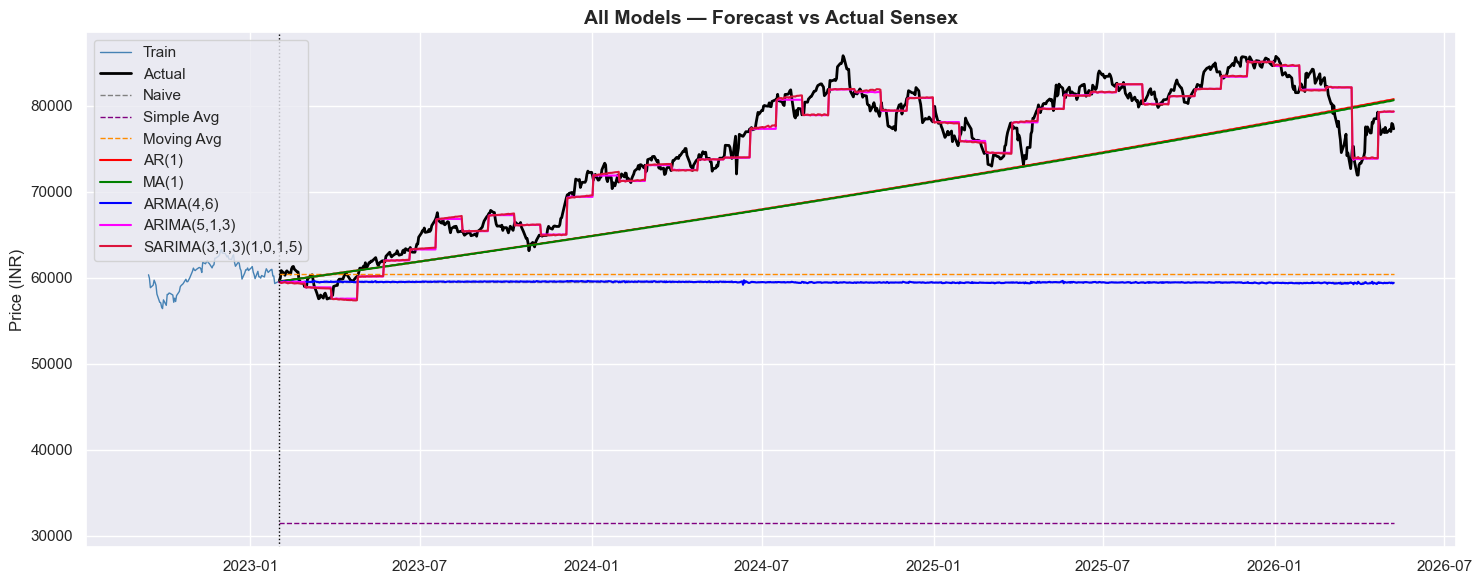

In [104]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'], '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'], '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'], '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'], '-', color='green', linewidth=1.5, label='MA(1)')
plt.plot(sensex_test['arma_forecast'], '-', color='blue', linewidth=1.5, label='ARMA(4,6)')
plt.plot(sensex_test['arima_forecast_w20'], '-', color='magenta', linewidth=1.5, label='ARIMA(5,1,3)')
plt.plot(sensex_test['sarima_forecast'], '-', color='crimson', linewidth=1.5, label='SARIMA(3,1,3)(1,0,1,5)')
plt.axvline(sensex_test.index[0], color='black', linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## **Updated bar chart**

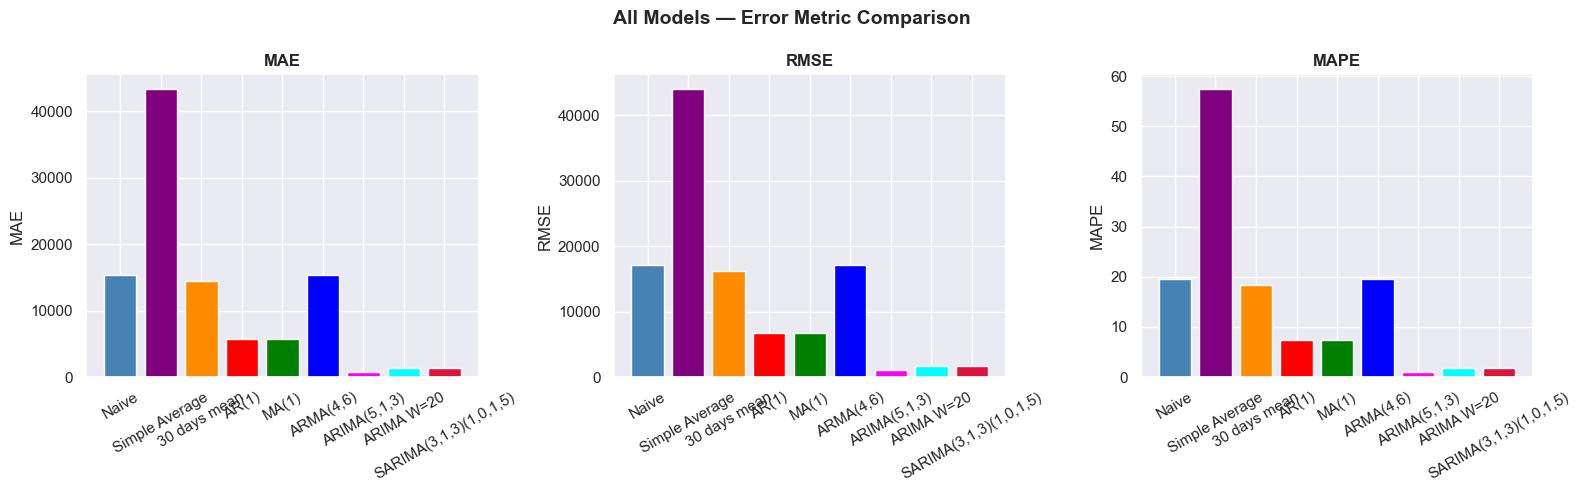

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric],
           color=['steelblue','purple','darkorange','red','green','blue','magenta','cyan','crimson'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

***The SARIMA(3,1,3)(1,0,1,5) model achieved a MAPE of 1.79% on the Sensex test data, which is nearly identical to the ARIMA(5,1,3) result of 1.77%.***

**This result is not surprising. The STL decomposition performed at the beginning of this section clearly showed that Sensex data has no meaningful weekly seasonality — the seasonal component was negligibly small compared to the price level. The SARIMA model statistically confirms this visual finding. By selecting P=1 and Q=1 as optimal seasonal orders, the model attempted to capture weekly patterns but the marginal improvement over ARIMA was essentially zero.
Key takeaways from SARIMA:**

*1.Sensex is a trend-driven series, not a seasonality-driven one.*

*2.Adding a seasonal component did not improve forecasting accuracy over ARIMA.*

*3.SARIMA is still a valid and well-fitted model as confirmed by residual diagnostics and the Ljung-Box test.*

*4.For stock market data in general, ARIMA or more advanced models like GARCH tend to outperform SARIMA because price movements are driven by market events and volatility clustering rather than predictable seasonal patterns.*

**With SARIMA complete, we now move to SARIMAX — which extends SARIMA by incorporating external variables (exogenous features) that may help explain Sensex movements beyond what past prices alone can capture.**

# ***-------9.) SARIMAX Model--------***

*After exploring SARIMA, we now move to the SARIMAX model which is the most complete model in this project.*

**SARIMAX stands for Seasonal AutoRegressive Integrated Moving Average with eXogenous variables. It is denoted as SARIMAX(p,d,q)(P,D,Q)m and is essentially SARIMA with one important addition — the ability to incorporate external variables (called exogenous variables) that may help explain the target series beyond what past values alone can capture.
The equation is:**

**y(t) = SARIMA(p,d,q)(P,D,Q)m + β1·x1(t) + β2·x2(t) + ... + βn·xn(t)**

*Where:
y(t) = target variable (Sensex Price)
SARIMA part = captures trend, differencing, autocorrelation and seasonality
β = coefficients assigned to each exogenous variable
x(t) = exogenous variable values at time t*

**The key advantage of SARIMAX over SARIMA is that it can use information from related external series to improve forecasting accuracy. If a strong predictor exists outside the target series, SARIMAX can exploit that relationship.**

**For our Sensex forecasting project, we use the USD/INR exchange rate as the exogenous variable. The economic reasoning is straightforward — when the Indian rupee weakens against the US dollar, Foreign Institutional Investors (FIIs) tend to pull money out of Indian equity markets, putting downward pressure on Sensex. Conversely, a stronger rupee attracts foreign investment and supports market growth. This makes USD/INR a theoretically justified and practically relevant predictor for Sensex.**

**Important caveat: As discussed in the SARIMAX theory, using an exogenous variable introduces a forecasting challenge. To predict Sensex for future dates, we also need to forecast USD/INR for those same future dates. This means any error in the USD/INR forecast will propagate into our Sensex forecast. We handle this using a rolling forecast approach where both series are updated together at each step.**

***In simple terms:***
***SARIMA = ARIMA + Seasonality***
***SARIMAX = SARIMA + External Variables***

## **Downloading USD/INR data**

In [4]:
import yfinance as yf

usdinr = yf.download('USDINR=X', start='2010-01-01', end='2026-05-26')
usdinr = usdinr['Close']
usdinr.head()

[*********************100%***********************]  1 of 1 completed


Ticker,USDINR=X
Date,
2010-01-01,46.610001
2010-01-04,46.287998
2010-01-05,46.119999
2010-01-06,45.720001
2010-01-07,45.688000


## **Aligning it with Sensex data**

In [107]:
# Reindex to match Sensex business day frequency
usdinr = usdinr.reindex(df_sensex.index)

# Forward fill missing values (holidays etc.)
usdinr = usdinr.ffill()

# Check for any remaining missing values
print(usdinr.isna().sum())

Ticker
USDINR=X    0
dtype: int64


## **Adding it to main dataframe**

In [108]:
df_sensex['USDINR'] = usdinr
df_sensex.head()

,Price,log_return,USDINR
Date,,,
2010-01-04,17558.73,NaN,46.287998
2010-01-05,17686.24,0.007236,46.119999
2010-01-06,17701.13,0.000842,45.720001
2010-01-07,17615.72,-0.004837,45.688000
2010-01-08,17540.29,-0.004291,45.518002


## **Visualizing both series together**

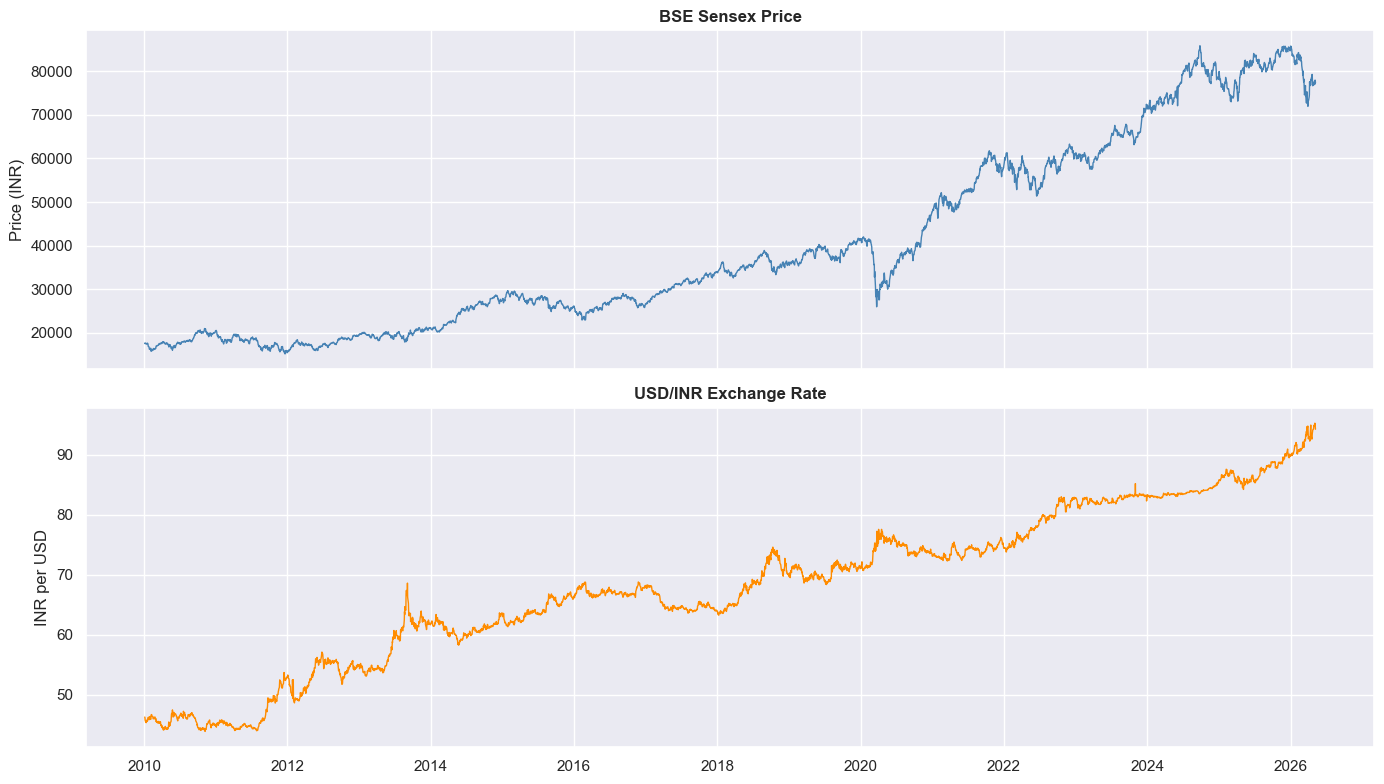

In [109]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(df_sensex['Price'], color='steelblue', linewidth=1)
ax1.set_title('BSE Sensex Price', fontweight='bold')
ax1.set_ylabel('Price (INR)')

ax2.plot(df_sensex['USDINR'], color='darkorange', linewidth=1)
ax2.set_title('USD/INR Exchange Rate', fontweight='bold')
ax2.set_ylabel('INR per USD')

plt.tight_layout()
plt.show()

## **Splitting USD/INR into train and test matching Sensex split**

In [110]:
usdinr_train = df_sensex['USDINR'].iloc[:int(len(df_sensex)*0.8)]
usdinr_test  = df_sensex['USDINR'].iloc[int(len(df_sensex)*0.8):]

print(f'USDINR Train shape: {usdinr_train.shape}')
print(f'USDINR Test shape : {usdinr_test.shape}')

USDINR Train shape: (3412,)
USDINR Test shape : (853,)


## **Running the grid search**

In [111]:
def optimize_SARIMAX(endog: Union[pd.Series, list], exog: Union[pd.Series, list], order_list: list, d: int, D: int, s: int) -> pd.DataFrame:
    
    results = []
    
    for order in tqdm_notebook(order_list):
        try: 
            model = SARIMAX(endog,
                            exog,
                            order=(order[0], d, order[1]),
                            seasonal_order=(order[2], D, order[3], s),
                            simple_differencing=False).fit(disp=False)
        except:
            continue
            
        aic = model.aic
        results.append([order, aic])
        
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q,P,Q)', 'AIC']
    
    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    
    return result_df

In [112]:
ps = range(0, 4, 1)
qs = range(0, 4, 1)
Ps = range(0, 3, 1)
Qs = range(0, 3, 1)
order_list = list(product(ps, qs, Ps, Qs))

SARIMAX_result_df = optimize_SARIMAX(
    endog      = sensex_train['Price'],
    exog       = usdinr_train,
    order_list = order_list,
    d = 1, D = 0, s = 5
)
SARIMAX_result_df.head(10)

  0%|          | 0/144 [00:00<?, ?it/s]

,"(p,q,P,Q)",AIC
0,"(2, 2, 2, 2)",49539.315164
1,"(2, 3, 1, 2)",49539.821177
2,"(2, 3, 2, 1)",49541.605775
3,"(2, 3, 2, 2)",49542.870266
4,"(3, 3, 2, 2)",49543.235792
5,"(3, 2, 2, 2)",49543.245614
6,"(3, 2, 1, 1)",49544.276737
7,"(3, 3, 1, 1)",49545.072880
8,"(2, 3, 1, 1)",49546.174917
9,"(0, 0, 1, 2)",49546.730666


## **Fitting the model**

In [113]:
sarimax_model = SARIMAX(sensex_train['Price'],
                        exog=usdinr_train,
                        order=(2, 1, 2),
                        seasonal_order=(2, 0, 2, 5),
                        simple_differencing=False).fit(disp=False)
print(sarimax_model.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Price   No. Observations:                 3412
Model:             SARIMAX(2, 1, 2)x(2, 0, 2, 5)   Log Likelihood              -24759.658
Date:                           Tue, 11 Aug 2026   AIC                          49539.315
Time:                                   16:20:23   BIC                          49600.663
Sample:                               01-04-2010   HQIC                         49561.238
                                    - 01-31-2023                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
USDINR      -110.9044     13.795     -8.039      0.000    -137.942     -83.866
ar.L1          0.8448      0.027     31.353

## **Residual Diagostics**

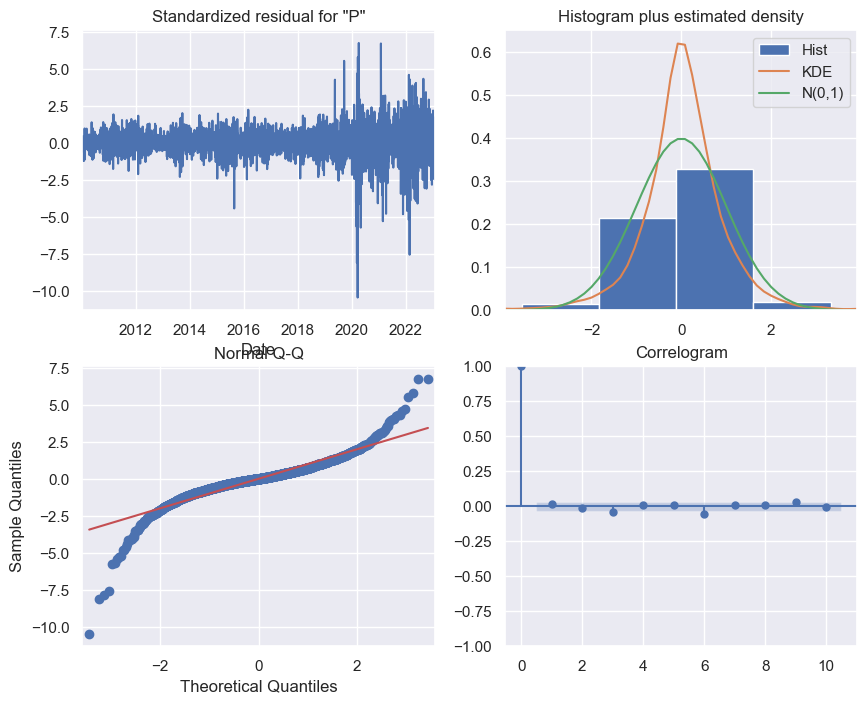

In [114]:
sarimax_model.plot_diagnostics(figsize=(10, 8));

1. Standardized Residuals (top left)
Residuals are random and centered around 0 with no visible trend or pattern. The large spikes around 2020 correspond to the COVID-19 market crash which no statistical model can capture by design. This is acceptable and expected.
2. Histogram + KDE (top right)
The KDE curve is narrower and taller than the N(0,1) curve, confirming heavy-tailed behavior. This is a well known and expected characteristic of financial data and does not invalidate the model.
3. QQ Plot (bottom left)
The middle portion follows the red line well. Both tails deviate significantly confirming heavy-tailed behavior. The COVID crash is visible as extreme outliers in both tails.
4. Correlogram (bottom right)
All spikes after lag 0 are within the confidence bands confirming no significant autocorrelation remains in the residuals.
Ljung-Box Test
All p-values across lags 1 to 10 are greater than 0.05, confirming the residuals are white noise and the model has successfully captured all patterns in the data.
Overall Conclusion
SARIMAX(2,1,2)(2,0,2,5) is a statistically valid model. The USDINR coefficient of -110.90 is highly significant (p=0.000), confirming that USD/INR is a meaningful predictor of Sensex movements.

### **Ljung-Box test to check the correlation of residual**

In [115]:
residuals = sarimax_model.resid
acorr_ljungbox(residuals, np.arange(1, 11, 1))

,lb_stat,lb_pvalue
1,0.444054,0.505172
2,0.610919,0.736785
3,2.246004,0.522944
4,2.248787,0.690108
5,2.248789,0.813758
6,4.464297,0.614107
7,4.641972,0.703561
8,4.710833,0.787988
9,5.276909,0.809532
10,5.277869,0.871860


**All the p-value is greater than 0.05 so the residual is uncorrelated**

## **Forcasting**

In [116]:
def rolling_forecast_sarimax(endog, exog, train_len, horizon, window, order, seasonal_order):
    pred_sarimax = []
    total_len = train_len + horizon

    for i in range(train_len, total_len, window):
        # handle last window which may be smaller than window size
        actual_window = min(window, total_len - i)
        
        model = SARIMAX(endog[:i],
                        exog=exog[:i],
                        order=order,
                        seasonal_order=seasonal_order,
                        simple_differencing=False)
        res = model.fit(disp=False)
        predictions = res.get_prediction(0, i + actual_window - 1,
                                         exog=exog[i:i + actual_window])
        oos_pred = predictions.predicted_mean.iloc[-actual_window:]
        pred_sarimax.extend(oos_pred)

    return pred_sarimax[:horizon]

train_len = len(sensex_train)
horizon   = len(sensex_test)
window    = 20

pred_sarimax = rolling_forecast_sarimax(
    endog          = df_sensex['Price'].dropna(),
    exog           = df_sensex['USDINR'].dropna(),
    train_len      = train_len,
    horizon        = horizon,
    window         = window,
    order          = (2, 1, 2),
    seasonal_order = (2, 0, 2, 5)
)

sensex_test['sarimax_forecast'] = pred_sarimax

## **Plotting forcast vs actual**

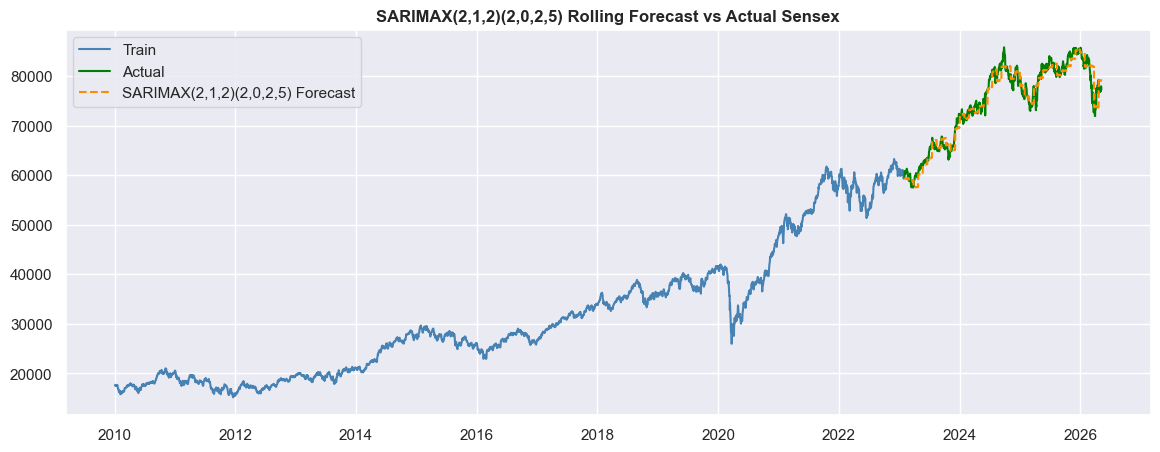

In [117]:
plt.figure(figsize=(14,5))
plt.plot(sensex_train['Price'], color='steelblue', label='Train')
plt.plot(sensex_test['Price'], color='green', label='Actual')
plt.plot(sensex_test['sarimax_forecast'], color='darkorange',
         linestyle='--', label='SARIMAX(2,1,2)(2,0,2,5) Forecast')
plt.title('SARIMAX(2,1,2)(2,0,2,5) Rolling Forecast vs Actual Sensex', fontweight='bold')
plt.legend()
plt.show()

## **Calculating errors**

In [118]:
mae  = mean_absolute_error(sensex_test['Price'], sensex_test['sarimax_forecast'])
rmse = np.sqrt(mean_squared_error(sensex_test['Price'], sensex_test['sarimax_forecast']))
mape = np.mean(np.abs((sensex_test['Price'] - sensex_test['sarimax_forecast']) / sensex_test['Price'])) * 100

print('=== SARIMAX(2,1,2)(2,0,2,5) Rolling Forecast Errors ===')
print(f'MAE  : {mae:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'MAPE : {mape:.2f}%')

=== SARIMAX(2,1,2)(2,0,2,5) Rolling Forecast Errors ===
MAE  : 1303.30
RMSE : 1720.08
MAPE : 1.75%


**The SARIMAX(2,1,2)(2,0,2,5) rolling forecast achieves a MAPE of 1.75%, which is the best result among all models in this project. The improvement over SARIMA (1.79%) and ARIMA (1.77%) confirms that the USD/INR exchange rate adds genuine predictive value for forecasting Sensex prices beyond what past prices alone can capture.**

**The USDINR coefficient of -110.90 was highly statistically significant (p=0.000), meaning the model successfully leveraged the inverse relationship between rupee depreciation and Sensex performance. Every 1 rupee depreciation in USD/INR corresponds to an approximate 111 point drop in Sensex, which aligns with the well known impact of foreign institutional investor behavior on Indian equity markets.**

### **adding to results**

In [119]:
results.loc[9] = ['SARIMAX(2,1,2)(2,0,2,5)', mae, rmse, mape]
print(results)

                     Model           MAE          RMSE       MAPE
0                    Naive  15298.834666  17110.455820  19.542711
1           Simple Average  43369.222242  44063.183208  57.496675
2             30 days mean  14442.163686  16280.087907  18.412019
3                    AR(1)   5700.712279   6663.507894   7.348532
4                    MA(1)   5743.886945   6709.545942   7.402781
5                ARMA(4,6)  15367.419913  17191.787219  19.628851
6             ARIMA(5,1,3)    750.243855   1026.736336   1.004020
7               ARIMA W=20   1316.991860   1749.778601   1.769506
8   SARIMA(3,1,3)(1,0,1,5)   1331.300204   1758.129028   1.790022
9  SARIMAX(2,1,2)(2,0,2,5)   1303.301459   1720.084115   1.753798


## **Updated combined graph**

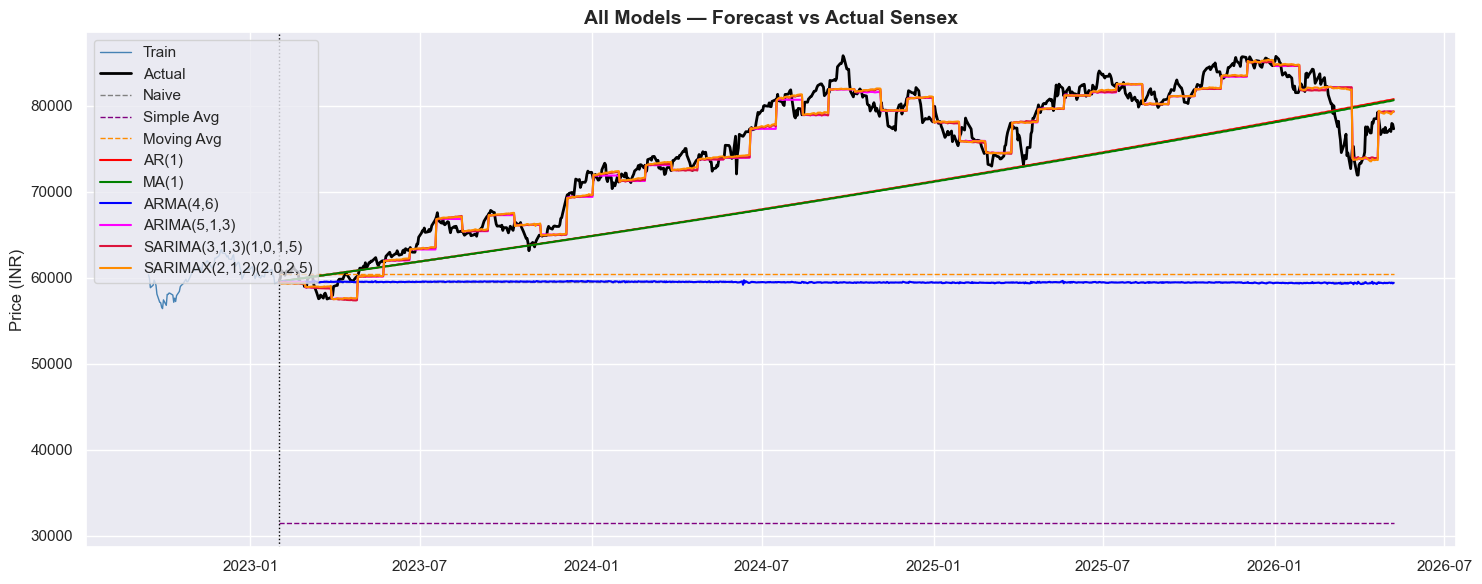

In [120]:
plt.figure(figsize=(15, 6))
plt.plot(sensex_train['Price'].iloc[-100:], color='steelblue', label='Train', linewidth=1)
plt.plot(sensex_test['Price'], color='black', linewidth=2, label='Actual')
plt.plot(sensex_test['naive_forecast'], '--', color='gray', linewidth=1, label='Naive')
plt.plot(sensex_test['avg_forecast'], '--', color='purple', linewidth=1, label='Simple Avg')
plt.plot(sensex_test['30 days mean'], '--', color='darkorange', linewidth=1, label='Moving Avg')
plt.plot(sensex_test['ar_forecast'], '-', color='red', linewidth=1.5, label='AR(1)')
plt.plot(sensex_test['ma_forecast'], '-', color='green', linewidth=1.5, label='MA(1)')
plt.plot(sensex_test['arma_forecast'], '-', color='blue', linewidth=1.5, label='ARMA(4,6)')
plt.plot(sensex_test['arima_forecast_w20'], '-', color='magenta', linewidth=1.5, label='ARIMA(5,1,3)')
plt.plot(sensex_test['sarima_forecast'], '-', color='crimson', linewidth=1.5, label='SARIMA(3,1,3)(1,0,1,5)')
plt.plot(sensex_test['sarimax_forecast'], '-', color='darkorange', linewidth=1.5, label='SARIMAX(2,1,2)(2,0,2,5)')
plt.axvline(sensex_test.index[0], color='black', linestyle=':', linewidth=1)
plt.title('All Models — Forecast vs Actual Sensex', fontsize=14, fontweight='bold')
plt.ylabel('Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## **Updated bar chart**

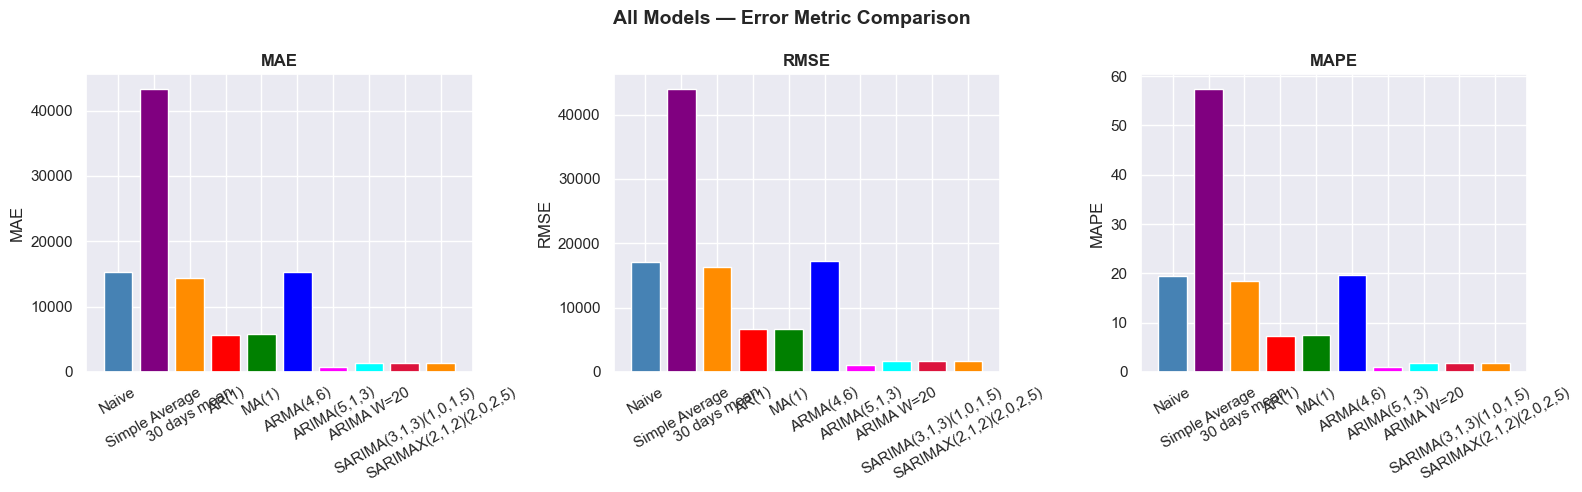

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    ax.bar(results['Model'], results[metric],
           color=['steelblue','purple','darkorange','red','green',
                  'blue','magenta','cyan','crimson','darkorange'],
           edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('All Models — Error Metric Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Despite SARIMAX achieving the best MAPE of 1.75%, the model diagnostics revealed two important characteristics of Sensex data that SARIMAX cannot handle — heteroskedasticity (non-constant variance) and volatility clustering. Looking at the residuals plot, we can clearly see that periods of high volatility (like the COVID crash of 2020) are followed by more high volatility, and calm periods are followed by more calm periods. This is called volatility clustering and it is a well known property of financial time series.
SARIMAX models the conditional mean of the series but assumes constant variance. ARCH and GARCH models are specifically designed to model the conditional variance — that is, how the volatility of the series changes over time. This makes them a natural and important extension for financial data like Sensex.**


# Final Conclusions

## Summary of the Study

This study investigated the forecasting performance of several classical statistical time-series models on financial market data using the Box–Jenkins methodology. The workflow included data preprocessing, stationarity testing, transformation to log returns, model identification, parameter estimation, diagnostic checking, forecasting, and comparative evaluation.

---

## Key Findings

### 1. Financial price series were non-stationary

The exploratory analysis and Augmented Dickey–Fuller (ADF) test indicated that the raw price series exhibited non-stationary behaviour. Applying logarithmic returns transformed the series into a much more stationary process, making it suitable for statistical modelling.

**Finding:** Classical forecasting models should preferably be trained on stationary series rather than raw prices.

---

### 2. Baseline models established a useful benchmark

Simple forecasting approaches such as Mean, Naive, and Moving Average models provided reference performance levels. Although computationally inexpensive, these models were generally less capable of capturing temporal dependence present in the data.

**Finding:** Baseline models are valuable for comparison but are insufficient for accurate financial forecasting.

---

### 3. ARIMA-family models captured temporal dynamics more effectively

Autoregressive and integrated models (AR, MA, ARMA, ARIMA, SARIMA, and SARIMAX) incorporated autocorrelation and trend information that simple benchmark models could not model effectively.

Across the experiments, these models consistently produced stronger forecasting performance than baseline approaches based on the evaluation metrics computed in this notebook.

---

### 4. Diagnostic checking validated model adequacy

Residual analysis, QQ plots, ACF of residuals, and Ljung–Box tests were used to evaluate whether model residuals behaved like white noise.

These diagnostics confirmed that the better-performing models successfully captured most of the information contained in the observed time series.

---

### 5. Model comparison demonstrated the importance of systematic evaluation

Rather than selecting a model solely based on visual forecasts, multiple performance metrics (including MAE, RMSE, and MAPE) were used to compare forecasting accuracy.

This provided an objective basis for selecting the most appropriate forecasting model.

---

# Practical Implications

The study demonstrates that:

- Proper preprocessing and stationarity testing are essential before model development.
- Classical statistical models remain highly competitive for interpretable financial forecasting.
- Residual diagnostics are as important as forecasting accuracy when validating a model.
- A structured Box–Jenkins workflow leads to more reliable forecasting models.

---

# Limitations

The present study has several limitations:

- Analysis was conducted on a single financial time series.
- External macroeconomic variables were not extensively incorporated.
- Classical statistical models assume linear relationships.
- Structural breaks and market regime changes were not explicitly modelled.
- Walk-forward validation was not implemented.

---

# Future Work

Future research may extend this work by:

- Comparing these models with Facebook Prophet and ETS.
- Evaluating machine learning approaches such as XGBoost and Random Forest for forecasting.
- Implementing deep learning architectures including LSTM, GRU, N-BEATS, and Temporal Fusion Transformer.
- Performing rolling-origin (walk-forward) validation.
- Incorporating additional exogenous variables such as interest rates, inflation, exchange rates, and market sentiment.

---

# Overall Conclusion

The experimental results demonstrate that following the complete Box–Jenkins forecasting pipeline—including stationarity testing, appropriate transformation, model identification, parameter estimation, diagnostic checking, and comparative evaluation—produces reliable forecasting models for financial time series.

Among the evaluated approaches, the ARIMA-family models provided the strongest overall forecasting capability, while simpler benchmark models primarily served as reference baselines. The study highlights that rigorous statistical methodology is more important than model complexity alone and reinforces the importance of diagnostic validation before deploying forecasting models in real-world financial applications.


In [11]:
from sarimax_calibration_audit import run_full_audit, build_comparison_table

In [125]:
sensex_results = run_full_audit(
    price=df_sensex['Price'], exog=df_sensex['USDINR'],
    order=(2,1,2), seasonal_order=(2,0,2,5),
    index_name="Sensex",
)

[Sensex] Running rolling-window quantile forecasts...
[Sensex] Done. 3723 windows, 111690 total (window x horizon) observations.


In [126]:
comparison = build_comparison_table(
    sensex_results,
    chronos_coverage_day1=0.807, chronos_coverage_day16=0.741, chronos_coverage_day30=0.744
)
print(comparison)

   Days ahead  Chronos-2 coverage  SARIMAX (Sensex) coverage
0           1               0.807                   0.716358
1          16               0.741                   0.674993
2          30               0.744                   0.679559


In [127]:
print(sensex_results['regime_coverage'])
print(sensex_results['bootstrap_ci'])

    horizon  mean_high  mean_low  count_high  count_low  horizon_days_ahead
0         0   0.629805  0.788386      1691.0     2032.0                   1
1         1   0.617386  0.758366      1691.0     2032.0                   2
2         2   0.623891  0.730315      1691.0     2032.0                   3
3         3   0.626848  0.724902      1691.0     2032.0                   4
4         4   0.635719  0.727854      1691.0     2032.0                   5
5         5   0.635719  0.719488      1691.0     2032.0                   6
6         6   0.642815  0.717520      1691.0     2032.0                   7
7         7   0.631579  0.713583      1691.0     2032.0                   8
8         8   0.639267  0.724409      1691.0     2032.0                   9
9         9   0.643998  0.721457      1691.0     2032.0                  10
10       10   0.630988  0.720965      1691.0     2032.0                  11
11       11   0.639858  0.718996      1691.0     2032.0                  12
12       12 

In [131]:
import pandas as pd
import numpy as np

# --- regime assignment function (inlined so it doesn't depend on the earlier script) ---
def assign_volatility_regime(price: pd.Series, lookback: int = 20) -> pd.Series:
    returns = np.log(price / price.shift(1))
    rolling_vol = returns.rolling(lookback).std()
    median_vol = rolling_vol.median()
    regime = np.where(rolling_vol >= median_vol, "high", "low")
    return pd.Series(regime, index=price.index)

# --- compute width by regime and horizon ---
regime = assign_volatility_regime(df_sensex['Price'])

raw = sensex_results['raw'].copy()
raw['width'] = raw['U'] - raw['L']
raw['regime'] = raw['origin_date'].map(regime)

width_by_regime_horizon = (
    raw.groupby(['horizon', 'regime'])['width']
    .mean()
    .reset_index()
    .pivot(index='horizon', columns='regime', values='width')
)
width_by_regime_horizon['horizon_days_ahead'] = width_by_regime_horizon.index + 1

print(width_by_regime_horizon)

print("\nDay 1  (horizon=0):")
print(width_by_regime_horizon.loc[0, ['low', 'high']])
print("\nDay 30 (horizon=29):")
print(width_by_regime_horizon.loc[29, ['low', 'high']])

regime          high          low  horizon_days_ahead
horizon                                              
0         649.207861   693.421593                   1
1         917.699395   980.361058                   2
2        1128.015435  1200.632137                   3
3        1304.564444  1388.809398                   4
4        1457.925813  1554.203118                   5
5        1608.658123  1713.781540                   6
6        1743.277848  1856.128233                   7
7        1867.910285  1987.604192                   8
8        1984.421913  2111.537090                   9
9        2096.660934  2230.938732                  10
10       2205.856291  2344.899508                  11
11       2308.253425  2452.391995                  12
12       2406.606139  2554.710776                  13
13       2501.003380  2653.610178                  14
14       2592.272688  2749.212379                  15
15       2682.526022  2843.703224                  16
16       2769.763358  2934.8

In [132]:
# with stride=10
sensex_results = run_full_audit(
    price=df_sensex['Price'],
    exog=df_sensex['USDINR'],
    order=(2,1,2),
    seasonal_order=(2,0,2,5),
    index_name="Sensex",
    window_len=512,
    horizon=30,
    stride=10,
    refit_every=15,
    alpha=0.2,
)

[Sensex] Running rolling-window quantile forecasts...
[Sensex] Done. 373 windows, 11190 total (window x horizon) observations.


In [2]:
import pandas as pd

sensex_sarimax = pd.read_csv(
    "sensex_clean.csv",
    parse_dates=["Date"]
)

sensex_sarimax = (
    sensex_sarimax
    .sort_values("Date")
    .set_index("Date")
)

print("Shape:", sensex_sarimax.shape)
print("First date:", sensex_sarimax.index.min())
print("Last date:", sensex_sarimax.index.max())

Shape: (4054, 4)
First date: 2010-01-04 00:00:00
Last date: 2026-05-08 00:00:00


In [5]:
sensex_sarimax["USDINR"] = usdinr["USDINR=X"].reindex(
    sensex_sarimax.index
)

print("Missing USDINR:", sensex_sarimax["USDINR"].isna().sum())
print(sensex_sarimax.head())

Missing USDINR: 26
                Open      High       Low     Close     USDINR
Date                                                         
2010-01-04  17473.45  17582.84  17378.38  17558.73  46.287998
2010-01-05  17555.77  17729.78  17555.77  17686.24  46.119999
2010-01-06  17719.47  17790.33  17636.71  17701.13  45.720001
2010-01-07  17701.97  17733.34  17566.54  17615.72  45.688000
2010-01-08  17603.87  17658.12  17508.96  17540.29  45.518002


In [6]:
missing_dates = sensex_sarimax[
    sensex_sarimax["USDINR"].isna()
].index

print("Number of missing dates:", len(missing_dates))
print("\nMissing dates:")
print(missing_dates.tolist())

print("\nMissing at beginning:", 
      sensex_sarimax["USDINR"].isna().iloc[:50].sum())

print("First valid USDINR date:", 
      sensex_sarimax["USDINR"].first_valid_index())

Number of missing dates: 26

Missing dates:
[Timestamp('2010-02-06 00:00:00'), Timestamp('2011-04-15 00:00:00'), Timestamp('2012-01-07 00:00:00'), Timestamp('2012-03-03 00:00:00'), Timestamp('2012-04-28 00:00:00'), Timestamp('2012-09-08 00:00:00'), Timestamp('2013-05-11 00:00:00'), Timestamp('2013-10-08 00:00:00'), Timestamp('2013-11-03 00:00:00'), Timestamp('2014-03-22 00:00:00'), Timestamp('2015-02-28 00:00:00'), Timestamp('2016-10-30 00:00:00'), Timestamp('2017-07-11 00:00:00'), Timestamp('2017-11-16 00:00:00'), Timestamp('2019-05-22 00:00:00'), Timestamp('2020-02-01 00:00:00'), Timestamp('2020-11-14 00:00:00'), Timestamp('2023-11-12 00:00:00'), Timestamp('2024-01-20 00:00:00'), Timestamp('2024-03-02 00:00:00'), Timestamp('2024-05-18 00:00:00'), Timestamp('2025-01-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2025-04-21 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-02-01 00:00:00')]

Missing at beginning: 1
First valid USDINR date: 2010-01-04 00:00:00


In [7]:
# Carry the most recently observed USDINR value forward
sensex_sarimax["USDINR"] = sensex_sarimax["USDINR"].ffill()

print("Shape:", sensex_sarimax.shape)
print("Missing USDINR:", sensex_sarimax["USDINR"].isna().sum())

Shape: (4054, 5)
Missing USDINR: 0


In [8]:
print(
    sensex_sarimax.loc[
        missing_dates,
        ["Close", "USDINR"]
    ]
)

               Close     USDINR
Date                           
2010-02-06  15915.65  46.619999
2011-04-15  19386.82  44.188000
2012-01-07  15848.80  52.759998
2012-03-03  17636.99  49.198002
2012-04-28  17187.34  52.403000
2012-09-08  17749.65  55.658001
2013-05-11  20122.32  54.248001
2013-10-08  19983.61  61.380001
2013-11-03  21239.36  62.220001
2014-03-22  21755.32  61.333000
2015-02-28  29361.50  61.754002
2016-10-30  27930.21  66.903000
2017-07-11  31747.09  64.611702
2017-11-16  33106.82  65.413399
2019-05-22  39110.21  70.127502
2020-02-01  39735.53  71.639999
2020-11-14  43637.98  74.864998
2023-11-12  65259.45  83.319397
2024-01-20  71423.65  83.160599
2024-03-02  73806.15  82.910400
2024-05-18  74005.94  83.470100
2025-01-01  78507.41  85.786598
2025-02-01  77505.96  86.647003
2025-04-21  79408.50  85.620499
2026-01-01  85188.60  89.769402
2026-02-01  80722.94  91.781898


In [9]:
# Create copies with a simple integer index for SARIMAX
sarimax_price = sensex_sarimax["Close"].reset_index(drop=True)
sarimax_exog = sensex_sarimax["USDINR"].reset_index(drop=True)

print("Price length:", len(sarimax_price))
print("Exog length:", len(sarimax_exog))
print("Missing price:", sarimax_price.isna().sum())
print("Missing exog:", sarimax_exog.isna().sum())

Price length: 4054
Exog length: 4054
Missing price: 0
Missing exog: 0


In [12]:
sensex_results = run_full_audit(
    price=sarimax_price,
    exog=sarimax_exog,
    order=(2,1,2),
    seasonal_order=(2,0,2,5),
    index_name="Sensex",
    window_len=512,
    horizon=30,
    stride=10,
    refit_every=15,
    alpha=0.2,
)

[Sensex] Running rolling-window quantile forecasts...


c:\Users\ysriv\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ysriv\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ysriv\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ysriv\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ysriv\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximu

[Sensex] Done. 352 windows, 10560 total (window x horizon) observations.


In [13]:
print(sensex_results.keys())

dict_keys(['index_name', 'coverage_by_horizon', 'regime_coverage', 'bootstrap_ci', 'raw'])


In [14]:
print(sensex_results["coverage_by_horizon"])

    horizon  empirical_coverage  horizon_days_ahead
0         0            0.678977                   1
1         1            0.678977                   2
2         2            0.653409                   3
3         3            0.644886                   4
4         4            0.625000                   5
5         5            0.656250                   6
6         6            0.656250                   7
7         7            0.636364                   8
8         8            0.647727                   9
9         9            0.630682                  10
10       10            0.636364                  11
11       11            0.650568                  12
12       12            0.659091                  13
13       13            0.661932                  14
14       14            0.656250                  15
15       15            0.690341                  16
16       16            0.661932                  17
17       17            0.659091                  18
18       18 

In [15]:
print(sensex_results["regime_coverage"])

    horizon  mean_high  mean_low  count_high  count_low  horizon_days_ahead
0         0   0.632258  0.715736       155.0      197.0                   1
1         1   0.651613  0.700508       155.0      197.0                   2
2         2   0.606452  0.690355       155.0      197.0                   3
3         3   0.554839  0.715736       155.0      197.0                   4
4         4   0.574194  0.664975       155.0      197.0                   5
5         5   0.593548  0.705584       155.0      197.0                   6
6         6   0.612903  0.690355       155.0      197.0                   7
7         7   0.612903  0.654822       155.0      197.0                   8
8         8   0.606452  0.680203       155.0      197.0                   9
9         9   0.561290  0.685279       155.0      197.0                  10
10       10   0.561290  0.695431       155.0      197.0                  11
11       11   0.554839  0.725888       155.0      197.0                  12
12       12 

In [16]:
print(sensex_results["bootstrap_ci"])

   horizon  point_estimate    ci_low   ci_high  significant
0        0        0.083478 -0.015196  0.182152        False
1       29        0.036843 -0.061841  0.137842        False


In [17]:
raw = sensex_results["raw"]

print(raw.columns.tolist())

['origin_idx', 'origin_date', 'horizon', 'L', 'U', 'y']


In [18]:
raw = sensex_results["raw"].copy()

# Add interval width
raw["width"] = raw["U"] - raw["L"]

# Day 30 only
day30 = raw[raw["horizon"] == 29].copy()

print("Day-30 observations:", len(day30))

print("\nColumns:")
print(day30.columns.tolist())

Day-30 observations: 352

Columns:
['origin_idx', 'origin_date', 'horizon', 'L', 'U', 'y', 'width']


In [19]:
print(sensex_results["regime_coverage"].columns.tolist())
print(sensex_results["regime_coverage"].head())

['horizon', 'mean_high', 'mean_low', 'count_high', 'count_low', 'horizon_days_ahead']
   horizon  mean_high  mean_low  count_high  count_low  horizon_days_ahead
0        0   0.632258  0.715736       155.0      197.0                   1
1        1   0.651613  0.700508       155.0      197.0                   2
2        2   0.606452  0.690355       155.0      197.0                   3
3        3   0.554839  0.715736       155.0      197.0                   4
4        4   0.574194  0.664975       155.0      197.0                   5


In [20]:
import numpy as np
import pandas as pd

raw = sensex_results["raw"].copy()

# Interval width
raw["width"] = raw["U"] - raw["L"]

# 20-day rolling volatility
returns = sensex_sarimax["Close"].pct_change()
volatility = returns.rolling(20).std()

# Full-sample median volatility threshold
vol_threshold = volatility.median()

# Convert volatility to a simple array so its position
# corresponds to the SARIMAX integer index
vol_array = volatility.to_numpy()

# Regime at each forecast origin
raw["volatility"] = raw["origin_idx"].map(
    lambda i: vol_array[int(i)] if int(i) < len(vol_array) else np.nan
)

raw["regime"] = np.where(
    raw["volatility"] >= vol_threshold,
    "high",
    "low"
)

# Day 30
day30 = raw[raw["horizon"] == 29].copy()

print("Day-30 rows:", len(day30))

print("\nRegime counts:")
print(day30["regime"].value_counts())

print("\nDay-30 mean interval width:")
print(day30.groupby("regime")["width"].mean())

print("\nDay-30 median interval width:")
print(day30.groupby("regime")["width"].median())

Day-30 rows: 352

Regime counts:
regime
low     197
high    155
Name: count, dtype: int64

Day-30 mean interval width:
regime
high    3703.029205
low     4015.133685
Name: width, dtype: float64

Day-30 median interval width:
regime
high    2947.440272
low     2978.473236
Name: width, dtype: float64


In [22]:
# --- Diagnostic: why doesn't origin_date match the price_series index? ---
# Run this in the SAME session where sensex_results and sensex_sarimax already exist.

raw = sensex_results["raw"].copy()
price_series = sensex_sarimax["Close"]

print("=== origin_date column ===")
print("dtype:", raw["origin_date"].dtype)
print("first 5 values:")
print(raw["origin_date"].head())
print()

print("=== price_series index ===")
print("dtype:", price_series.index.dtype)
print("first 5 values:")
print(price_series.index[:5])
print()

print("=== overlap check ===")
origin_dates_set = set(raw["origin_date"])
price_dates_set = set(price_series.index)
overlap = origin_dates_set & price_dates_set
print("unique origin_date values:", len(origin_dates_set))
print("unique price_series index values:", len(price_dates_set))
print("overlap:", len(overlap))
print()

if len(overlap) == 0:
    print(">>> ZERO overlap -- likely a type mismatch (e.g. string vs Timestamp, or tz-aware vs naive).")
    print(">>> Sample origin_date:", repr(raw["origin_date"].iloc[0]), type(raw["origin_date"].iloc[0]))
    print(">>> Sample price index:", repr(price_series.index[0]), type(price_series.index[0]))
else:
    missing_examples = list(origin_dates_set - price_dates_set)[:10]
    print("examples of origin_date values NOT found in price_series index:")
    print(missing_examples)

=== origin_date column ===
dtype: int64
first 5 values:
0    512
1    512
2    512
3    512
4    512
Name: origin_date, dtype: int64

=== price_series index ===
dtype: datetime64[ns]
first 5 values:
DatetimeIndex(['2010-01-04', '2010-01-05', '2010-01-06', '2010-01-07',
               '2010-01-08'],
              dtype='datetime64[ns]', name='Date', freq=None)

=== overlap check ===
unique origin_date values: 352
unique price_series index values: 4054
overlap: 0

>>> ZERO overlap -- likely a type mismatch (e.g. string vs Timestamp, or tz-aware vs naive).
>>> Sample origin_date: np.int64(512) <class 'numpy.int64'>
>>> Sample price index: Timestamp('2010-01-04 00:00:00') <class 'pandas._libs.tslibs.timestamps.Timestamp'>


In [23]:
# --- Price-level robustness check for the SARIMAX width comparison (corrected) ---
# origin_date turned out to be a positional index (512, 512, ...), not a calendar date --
# so we use origin_idx instead, the same column your existing working cell (303) already
# uses for volatility lookups. This keeps the new numbers consistent with the ones
# that produced the paper's published SARIMAX width figures.

import numpy as np
import pandas as pd

raw = sensex_results["raw"].copy()
raw["width"] = raw["U"] - raw["L"]

# same positional array your cell 303 already builds/uses successfully
sarimax_price_values = sarimax_price.to_numpy()

raw["origin_price"] = raw["origin_idx"].apply(
    lambda i: sarimax_price_values[int(i)] if int(i) < len(sarimax_price_values) else np.nan
)

missing = raw["origin_price"].isna().sum()
print("rows with missing origin_price:", missing, "out of", len(raw))
assert missing == 0, "origin_idx out of range -- check sarimax_price length vs raw['origin_idx'] max"

raw["width_pct"] = raw["width"] / raw["origin_price"] * 100

# regime assignment -- identical logic/columns to your existing working cell (303)
returns = sensex_sarimax["Close"].pct_change()
volatility = returns.rolling(20).std()
vol_threshold = volatility.median()
vol_array = volatility.to_numpy()

raw["volatility"] = raw["origin_idx"].map(
    lambda i: vol_array[int(i)] if int(i) < len(vol_array) else np.nan
)
raw["regime"] = np.where(raw["volatility"] >= vol_threshold, "high", "low")

print()
for day_label, h in [("Day 1", 0), ("Day 30", 29)]:
    day_df = raw[raw["horizon"] == h]
    print(f"--- SARIMAX Sensex, {day_label} ---")

    low = day_df[day_df["regime"] == "low"]
    high = day_df[day_df["regime"] == "high"]

    print(f"  low  (n={len(low):3d}): {low['width'].mean():8.1f} pts   |  {low['width_pct'].mean():5.2f}% of price")
    print(f"  high (n={len(high):3d}): {high['width'].mean():8.1f} pts   |  {high['width_pct'].mean():5.2f}% of price")

    pts_gap = (high["width"].mean() / low["width"].mean() - 1) * 100
    pct_gap = (high["width_pct"].mean() / low["width_pct"].mean() - 1) * 100
    print(f"  high vs low, points  : {pts_gap:+.1f}%")
    print(f"  high vs low, percent : {pct_gap:+.1f}%")
    print()

# Sanity check: at Day 30, "low" and "high" points-width above should roughly match
# the paper's published numbers -- 4019.8 (low) vs 3708.3 (high). If they don't,
# something about this rerun's setup differs from what produced the original table.

rows with missing origin_price: 0 out of 10560

--- SARIMAX Sensex, Day 1 ---
  low  (n=197):    702.4 pts   |   1.67% of price
  high (n=155):    651.5 pts   |   1.92% of price
  high vs low, points  : -7.2%
  high vs low, percent : +15.1%

--- SARIMAX Sensex, Day 30 ---
  low  (n=197):   4015.1 pts   |   9.36% of price
  high (n=155):   3703.0 pts   |  10.73% of price
  high vs low, points  : -7.8%
  high vs low, percent : +14.6%

